# Analisis eksploratif live chat dan Super Chat pada kanal VTuber YouTube

Proyek UTS Data Science (PSIKS2W002). Unit analisis adalah satu kanal
pada satu bulan, dari Maret 2021 hingga Juli 2022.

**Pertanyaan penelitian.** Bagaimana arah dan kekuatan hubungan antara
jumlah pengguna unik live chat dan jumlah Super Chat yang tercatat pada
kanal VTuber di YouTube dalam bulan yang sama?

## Bab 2 dan 3 — Sumber, pemuatan, dan pemeriksaan data

Unduh [VTuber 1B Elements versi 7](https://www.kaggle.com/datasets/uetchy/vtuber-livechat-elements/versions/7)
dan letakkan ketiga CSV di folder `data/`. Sesuaikan `DATA_DIR` jika
CSV berada di folder lain. Grafik disimpan di `figures/`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from matplotlib.ticker import FuncFormatter, LogLocator, NullFormatter, PercentFormatter

DATA_DIR = Path("data")
FIGURE_DIR = Path("figures")
nama_berkas = ("chat_stats.csv", "superchat_stats.csv", "channels.csv")

berkas_hilang = [nama for nama in nama_berkas if not (DATA_DIR / nama).is_file()]
if berkas_hilang:
    raise FileNotFoundError(
        f"CSV belum tersedia di {DATA_DIR.resolve()}: {', '.join(berkas_hilang)}. "
        "Ekstrak VTuber 1B Elements versi 7 ke folder tersebut atau sesuaikan DATA_DIR."
    )

FIGURE_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
awal, akhir = pd.Period("2021-03", freq="M"), pd.Period("2022-07", freq="M")
kunci = ["channelId", "period"]
tipe_kunci = {"channelId": "string", "period": "string"}

chat = pd.read_csv(DATA_DIR / "chat_stats.csv", dtype=tipe_kunci)
superchat = pd.read_csv(DATA_DIR / "superchat_stats.csv", dtype=tipe_kunci)
channels = pd.read_csv(DATA_DIR / "channels.csv", dtype={"channelId": "string"})

tabel_sumber = pd.DataFrame(
    [
        {"Berkas": nama, "Baris": len(tabel), "Kolom": tabel.shape[1], "Kunci": kunci_sumber}
        for nama, tabel, kunci_sumber in (
            ("chat_stats.csv", chat, ", ".join(kunci)),
            ("superchat_stats.csv", superchat, ", ".join(kunci)),
            ("channels.csv", channels, "channelId"),
        )
    ]
).set_index("Berkas")
display(tabel_sumber)

for tabel in (chat, superchat):
    if tabel[kunci].isna().any().any():
        raise ValueError("Tabel statistik memiliki kunci kanal atau bulan yang kosong.")
    tabel["period"] = pd.to_datetime(tabel["period"], format="%Y-%m").dt.to_period("M")

,Baris,Kolom,Kunci
Berkas,,,
chat_stats.csv,12468,8,"channelId, period"
superchat_stats.csv,10942,10,"channelId, period"
channels.csv,1358,8,channelId


In [3]:
coverage = chat.loc[chat["period"].between(awal, akhir)].merge(
    superchat.loc[superchat["period"].between(awal, akhir)],
    on=kunci,
    how="outer",
    validate="one_to_one",
    indicator="coverage",
)
analysis = coverage.loc[coverage["coverage"].ne("right_only")].merge(
    channels[["channelId", "affiliation"]],
    on="channelId",
    how="left",
    validate="many_to_one",
)
kolom_bulat = chat.select_dtypes(include="integer").columns.union(
    superchat.select_dtypes(include="integer").columns
)
analysis = analysis.astype({kolom: "Int64" for kolom in kolom_bulat})
analysis["affiliation"] = analysis["affiliation"].astype("category")

kolom_utama = ["uniqueChatters", "superChats"]
matched = analysis.dropna(subset=kolom_utama).copy()
status_cakupan = {"both": "Kedua tabel", "left_only": "Hanya live chat", "right_only": "Hanya Super Chat"}
display(
    coverage["coverage"].value_counts(sort=False).rename(index=status_cakupan)
    .rename("Jumlah pengamatan").to_frame()
)
print(f"Tabel analisis: {len(analysis):,} pengamatan, {analysis['channelId'].nunique():,} kanal.")
display(analysis[kunci + kolom_utama].head())
analysis.info(show_counts=True)
kolom_profil = kunci + kolom_utama + ["affiliation"]
display(
    pd.DataFrame({
        "Tipe data": analysis[kolom_profil].dtypes.astype(str),
        "Nilai terisi": analysis[kolom_profil].count(),
        "Nilai hilang": analysis[kolom_profil].isna().sum(),
    }).rename_axis("Kolom")
)

Tabel analisis: 12,468 pengamatan, 1,248 kanal.
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12468 entries, 0 to 12467
Data columns (total 18 columns):
 #   Column                Non-Null Count  Dtype    
---  ------                --------------  -----    
 0   channelId             12468 non-null  string   
 1   period                12468 non-null  period[M]
 2   chats                 12468 non-null  Int64    
 3   memberChats           12468 non-null  Int64    
 4   uniqueChatters        12468 non-null  Int64    
 5   uniqueMembers         12468 non-null  Int64    
 6   bannedChatters        12468 non-null  Int64    
 7   deletedChats          12468 non-null  Int64    
 8   superChats            10941 non-null  Int64    
 9   uniqueSuperChatters   10941 non-null  Int64    
 10  totalSC               10941 non-null  Int64    
 11  averageSC             10941 non-null  Int64    
 12  totalMessageLength    10941 non-null  Int64    
 13  averageMessageLength  10941 non-null  Int64

,Jumlah pengamatan
coverage,
Hanya live chat,1527
Hanya Super Chat,1
Kedua tabel,10941


,channelId,period,uniqueChatters,superChats
0,UC--A2dwZW7-M2kID0N6_lfA,2021-03,1112,71
1,UC--A2dwZW7-M2kID0N6_lfA,2021-04,1184,124
2,UC--A2dwZW7-M2kID0N6_lfA,2021-05,1791,407
3,UC--A2dwZW7-M2kID0N6_lfA,2021-06,1575,239
4,UC--A2dwZW7-M2kID0N6_lfA,2021-07,1504,199


,Tipe data,Nilai terisi,Nilai hilang
Kolom,,,
channelId,string,12468,0
period,period[M],12468,0
uniqueChatters,Int64,12468,0
superChats,Int64,10941,1527
affiliation,category,12440,28


### Eksplorasi awal pengamatan berpasangan

In [4]:
def angka_id(nilai, digit=0):
    return f"{nilai:,.{digit}f}".translate(str.maketrans({",": ".", ".": ","}))

def format_log(sumbu):
    sumbu.set_major_locator(LogLocator(base=10, subs=(1.0,)))
    sumbu.set_major_formatter(FuncFormatter(lambda nilai, _: angka_id(nilai)))
    sumbu.set_minor_formatter(NullFormatter())

def simpan_gambar(fig, nama):
    lokasi = FIGURE_DIR / nama
    fig.savefig(lokasi, dpi=250, facecolor="white")
    plt.close(fig)
    display(Image(filename=str(lokasi), width=900))

data = matched[kolom_utama]
print(f"Jumlah pengamatan berpasangan: {angka_id(len(data))}")

Jumlah pengamatan berpasangan: 10.941


In [5]:
stat_desc = pd.DataFrame({
    "Jumlah pengamatan": data.count(),
    "Rata-rata": data.mean().round(2),
    "Median": data.median(),
    "Modus": data.apply(
        lambda kolom: " dan ".join(str(int(nilai)) for nilai in kolom.mode())
    ),
    "Simpangan baku": data.std(ddof=1).round(2),
    "Varians": data.var(ddof=1).round(2),
    "Minimum": data.min(),
    "Maksimum": data.max(),
}).T.rename(columns={
    "uniqueChatters": "Pengguna unik live chat",
    "superChats": "Super Chat tercatat",
})

display(stat_desc)

,Pengguna unik live chat,Super Chat tercatat
Jumlah pengamatan,10941,10941
Rata-rata,5794.06,529.01
Median,1399.0,163.0
Modus,131 dan 156,1
Simpangan baku,12043.0,1323.8
Varians,145033775.77,1752441.99
Minimum,3,1
Maksimum,224155,49855


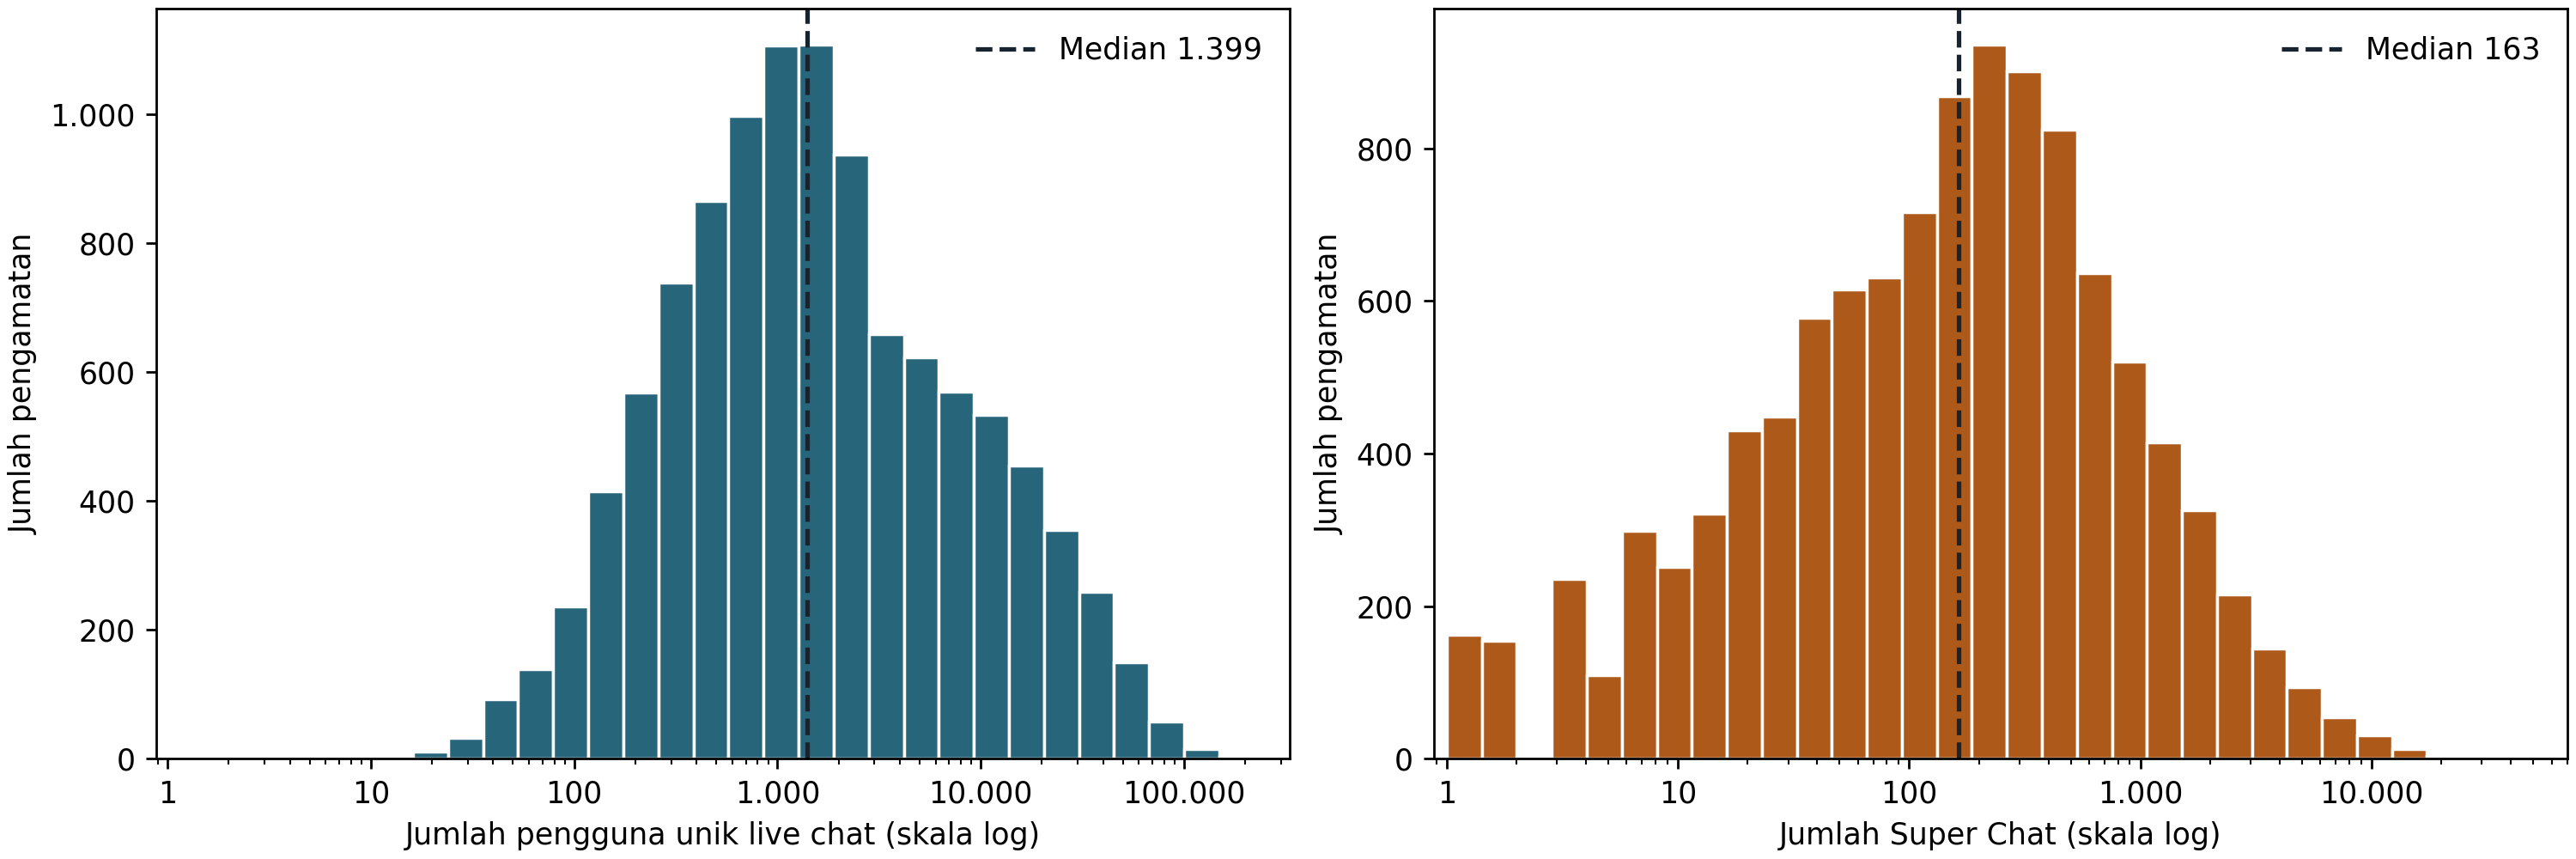

In [6]:
panel = [
    ("uniqueChatters", "Jumlah pengguna unik live chat", "#27657b", 330_000),
    ("superChats", "Jumlah Super Chat", "#ad591a", 70_000),
]

fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")

for ax, (kolom, label, warna, batas) in zip(axes, panel):
    nilai = data[kolom]
    bins = np.geomspace(1, batas, 33)
    ax.hist(nilai, bins=bins, color=warna, edgecolor="white")

    median = nilai.median()
    ax.axvline(
        median, color="#182330", linestyle="--",
        label=f"Median {angka_id(median)}",
    )
    ax.set(
        xscale="log", xlim=(0.88, batas),
        xlabel=f"{label} (skala log)", ylabel="Jumlah pengamatan",
    )
    format_log(ax.xaxis)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda nilai, _: angka_id(nilai)))
    ax.legend(frameon=False)

simpan_gambar(fig, "Gambar_2_1.png")

Korelasi Spearman: 0,723


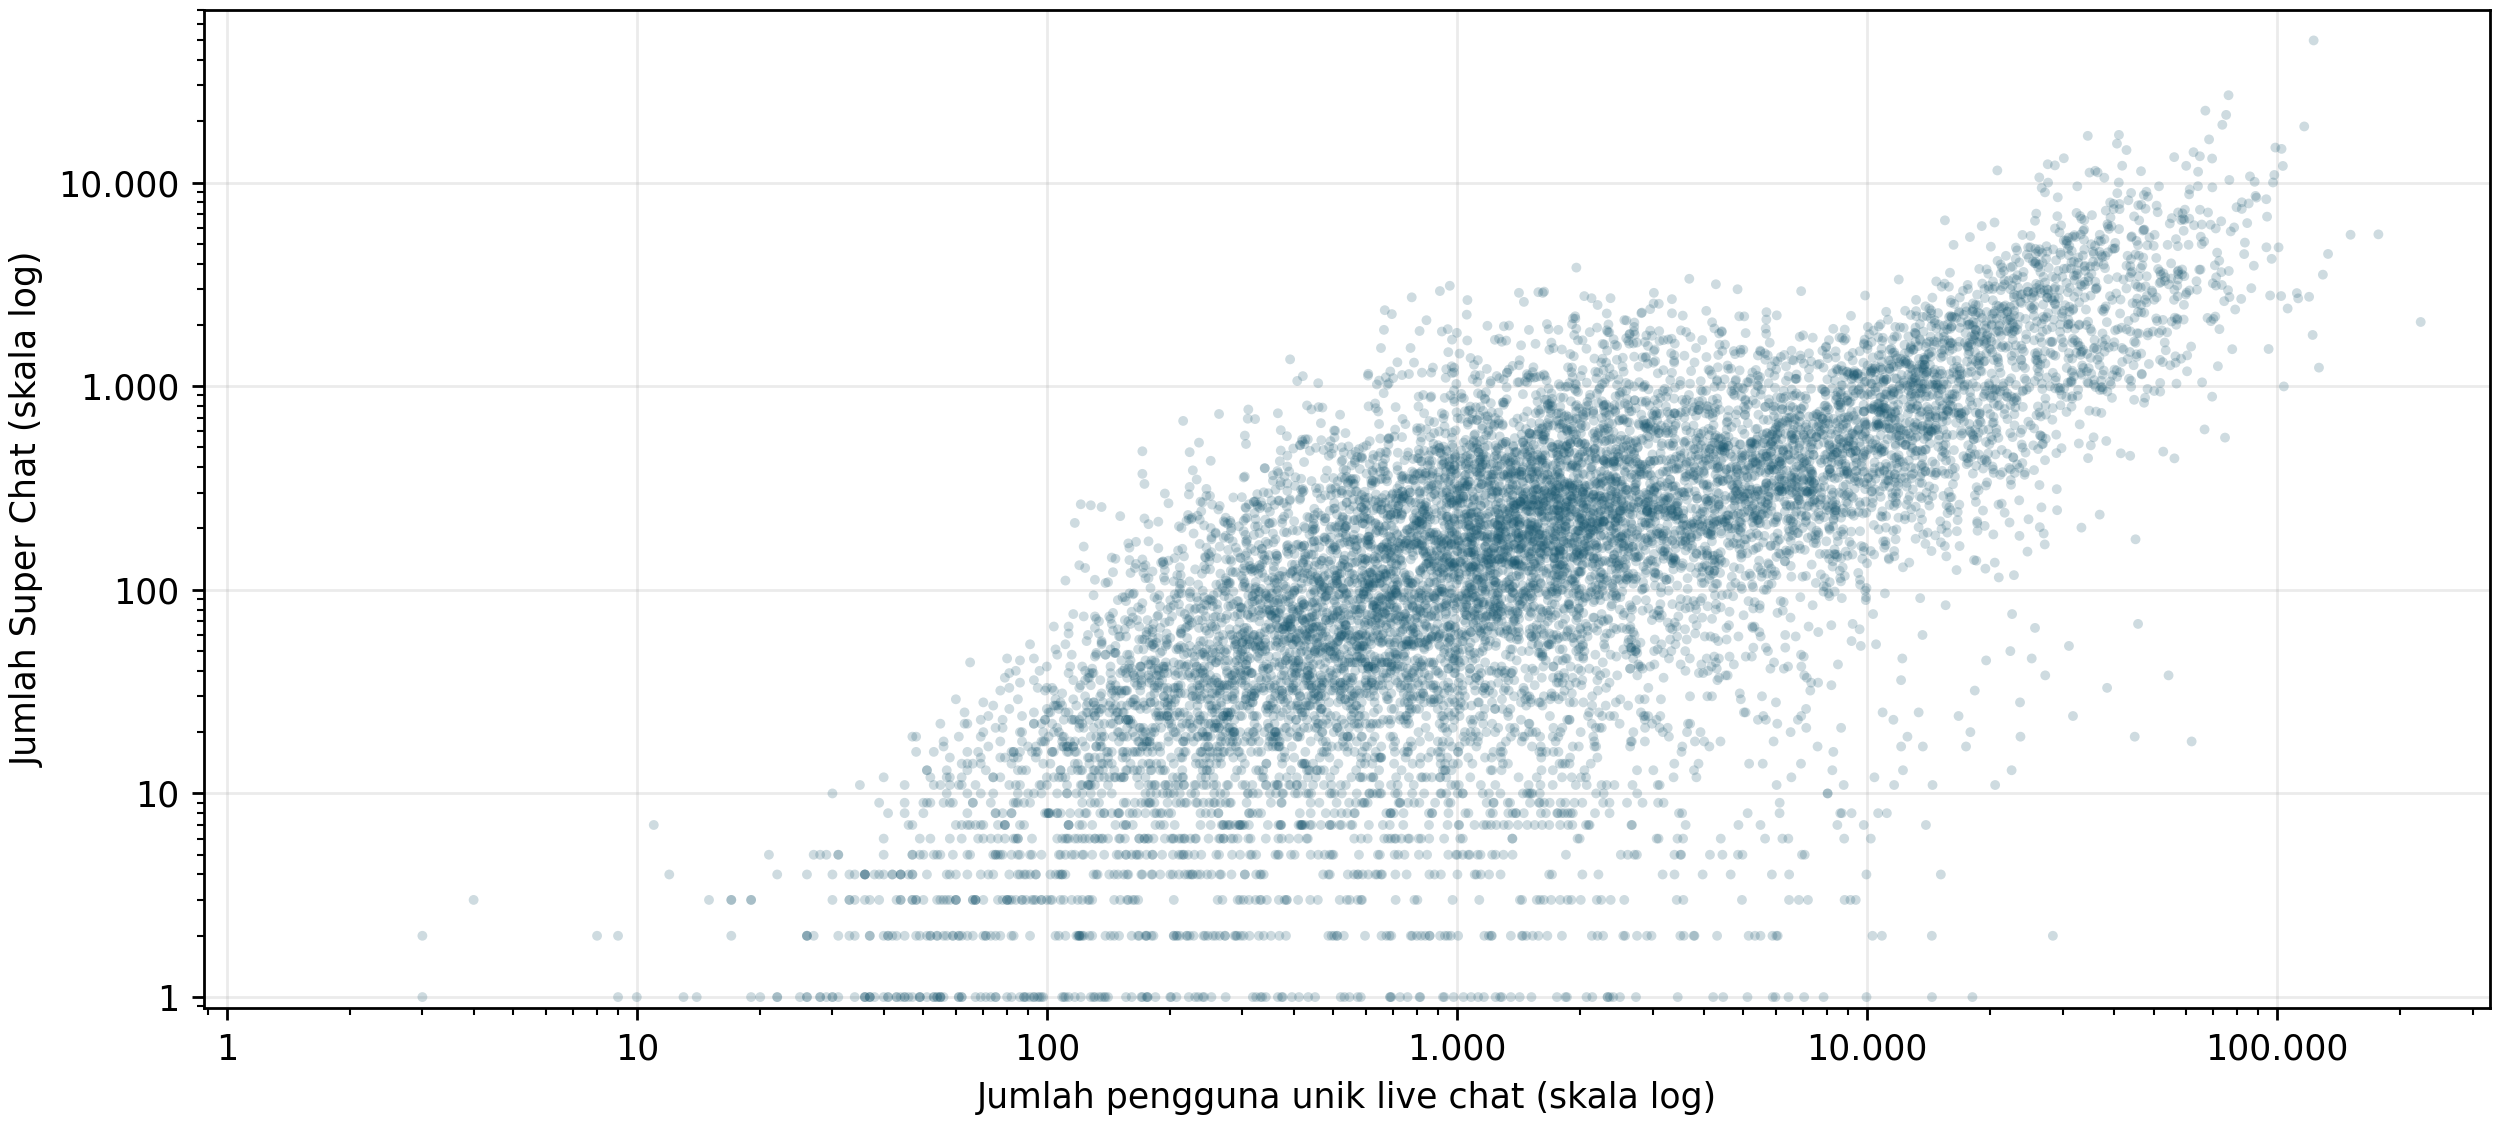

In [7]:
fig, ax = plt.subplots(figsize=(10, 4.5), layout="constrained")

ax.scatter(
    data["uniqueChatters"], data["superChats"],
    s=8, color="#18566e", alpha=0.21, edgecolors="none",
)
ax.set(
    xscale="log", yscale="log",
    xlim=(0.88, 330_000), ylim=(0.88, 70_000),
    xlabel="Jumlah pengguna unik live chat (skala log)",
    ylabel="Jumlah Super Chat (skala log)",
)
format_log(ax.xaxis)
format_log(ax.yaxis)
ax.set_axisbelow(True)
ax.grid(which="major", alpha=0.25)

simpan_gambar(fig, "Gambar_2_2.png")

rho = data["uniqueChatters"].corr(data["superChats"], method="spearman")
print("Korelasi Spearman:", angka_id(rho, 3))

## Bab 4 — Nilai hilang

Pengamatan live chat yang belum memiliki padanan Super Chat tetap
disimpan dengan nilai Super Chat kosong.

In [8]:
jumlah_hilang = analysis.isna().sum()
ringkasan_hilang = pd.DataFrame({
    "Jumlah hilang": jumlah_hilang,
    "Persentase (%)": (100 * jumlah_hilang / len(analysis)).round(2),
}).rename_axis("Kolom")
display(ringkasan_hilang.sort_values("Jumlah hilang", ascending=False, kind="stable"))

print("Sel kosong di chat_stats.csv:", chat.isna().sum().sum())
print("Sel kosong di superchat_stats.csv:", superchat.isna().sum().sum())
print("Nilai group kosong di channels.csv:", channels["group"].isna().sum())

Sel kosong di chat_stats.csv: 0
Sel kosong di superchat_stats.csv: 0
Nilai group kosong di channels.csv: 929


,Jumlah hilang,Persentase (%)
Kolom,,
superChats,1527,12.25
uniqueSuperChatters,1527,12.25
totalSC,1527,12.25
averageSC,1527,12.25
totalMessageLength,1527,12.25
averageMessageLength,1527,12.25
mostFrequentCurrency,1527,12.25
mostFrequentColor,1527,12.25
affiliation,28,0.22


### Pola nilai hilang menurut partisipasi live chat

In [9]:
superchat_hilang = analysis["superChats"].isna()
status_superchat = superchat_hilang.map({
    False: "Super Chat tercatat",
    True: "Super Chat belum diketahui",
})

ringkasan_status = analysis.groupby(status_superchat)["uniqueChatters"].agg(
    jumlah_pengamatan="size",
    median_pengguna_unik="median",
)
display(ringkasan_status)

kuartil = pd.qcut(
    analysis["uniqueChatters"], q=4, labels=["Q1", "Q2", "Q3", "Q4"]
)
ringkasan_kuartil = (
    analysis.assign(kuartil=kuartil, superchat_hilang=superchat_hilang)
    .groupby("kuartil", observed=True)
    .agg(
        jumlah_pengamatan=("superchat_hilang", "size"),
        jumlah_hilang=("superchat_hilang", "sum"),
        pengguna_unik_min=("uniqueChatters", "min"),
        pengguna_unik_maks=("uniqueChatters", "max"),
    )
)
ringkasan_kuartil["Persentase (%)"] = (
    100 * ringkasan_kuartil["jumlah_hilang"]
    / ringkasan_kuartil["jumlah_pengamatan"]
).round(2)
display(ringkasan_kuartil)

,jumlah_pengamatan,median_pengguna_unik
superChats,,
Super Chat belum diketahui,1527,356.0
Super Chat tercatat,10941,1399.0


,jumlah_pengamatan,jumlah_hilang,pengguna_unik_min,pengguna_unik_maks,Persentase (%)
kuartil,,,,,
Q1,3119,788,1,405,25.26
Q2,3118,309,406,1241,9.91
Q3,3114,272,1242,4314,8.73
Q4,3117,158,4317,224155,5.07


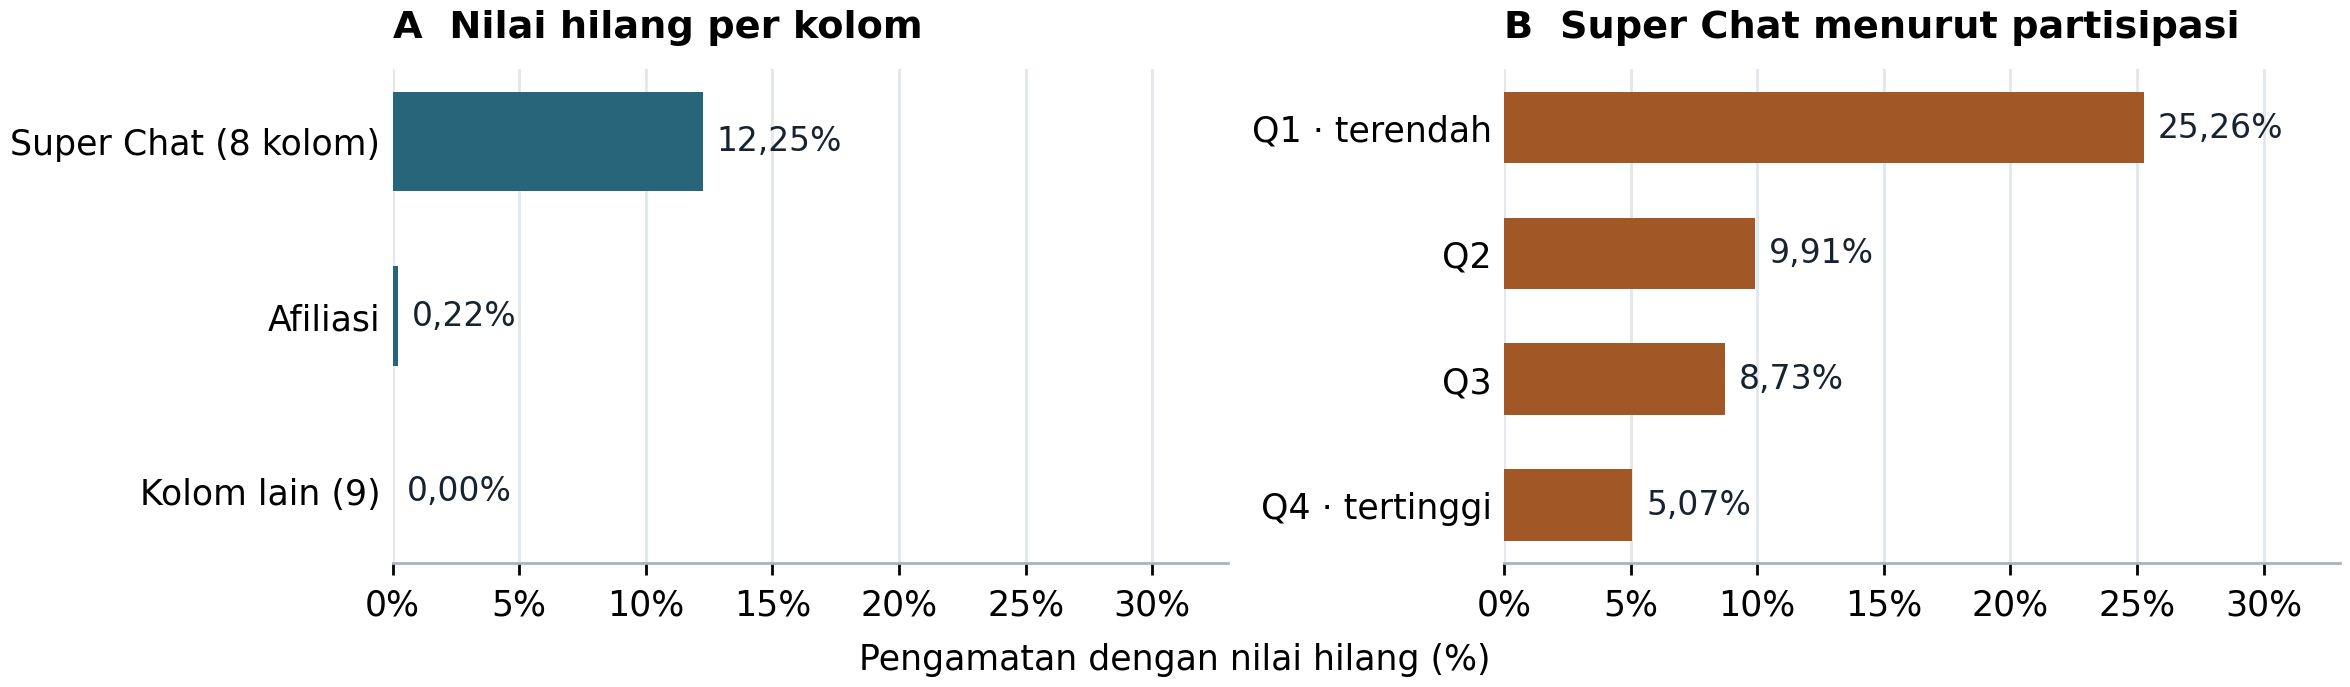

In [10]:
def diagram_persen(ax, label, persen, judul, warna):
    batang = ax.barh(label, persen, color=warna, height=0.57)
    teks = [f"{nilai:.2f}%".replace(".", ",") for nilai in persen]
    ax.bar_label(batang, labels=teks, padding=4, color="#182330", fontsize=9.5)
    ax.invert_yaxis()
    ax.set_xlim(0, 33)
    ax.set_xticks(range(0, 31, 5))
    ax.xaxis.set_major_formatter(PercentFormatter(100, decimals=0))
    ax.set_title(judul, loc="left", fontsize=11, fontweight="bold", pad=9)
    ax.set_axisbelow(True)
    ax.grid(axis="x", color="#e1e7eb", linewidth=0.8)
    ax.tick_params(axis="y", length=0)
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.spines["bottom"].set_color("#aab4bf")

fig, (kiri, kanan) = plt.subplots(
    1, 2, figsize=(9.4, 2.75), layout="constrained",
)
diagram_persen(
    kiri,
    ["Super Chat (8 kolom)", "Afiliasi", "Kolom lain (9)"],
    [
        ringkasan_hilang.loc["superChats", "Persentase (%)"],
        ringkasan_hilang.loc["affiliation", "Persentase (%)"],
        0,
    ],
    "A  Nilai hilang per kolom", "#27657b",
)
diagram_persen(
    kanan,
    ["Q1 · terendah", "Q2", "Q3", "Q4 · tertinggi"],
    ringkasan_kuartil["Persentase (%)"].tolist(),
    "B  Super Chat menurut partisipasi", "#a15726",
)
fig.supxlabel("Pengamatan dengan nilai hilang (%)", fontsize=10)
simpan_gambar(fig, "Gambar_4_1_Nilai_Hilang.png")

### Subset lengkap untuk korelasi

In [11]:
jumlah_dikecualikan = len(analysis) - len(matched)

print("Pengamatan pada tabel analysis:", len(analysis))
print("Pengamatan untuk korelasi:", len(matched))
print("Pengamatan di luar subset korelasi:", jumlah_dikecualikan)
print("Pasangan dengan afiliasi belum diketahui:", matched["affiliation"].isna().sum())

rho = matched["uniqueChatters"].corr(matched["superChats"], method="spearman")
print("Korelasi Spearman:", angka_id(rho, 3))

Pengamatan pada tabel analysis: 12468
Pengamatan untuk korelasi: 10941
Pengamatan di luar subset korelasi: 1527
Pasangan dengan afiliasi belum diketahui: 21
Korelasi Spearman: 0,723


### Label afiliasi yang belum diketahui

In [12]:
afiliasi_tampilan = analysis["affiliation"].astype("string").fillna("Tidak diketahui")
print("Pengamatan dengan label Tidak diketahui:", afiliasi_tampilan.eq("Tidak diketahui").sum())
print("Hitungan Super Chat yang belum diketahui:", analysis["superChats"].isna().sum())

Pengamatan dengan label Tidak diketahui: 28
Hitungan Super Chat yang belum diketahui: 1527


## Bab 5 — Statistik deskriptif dan distribusi

In [13]:
nama_variabel = {
    "uniqueChatters": "Pengguna unik live chat",
    "superChats": "Super Chat tercatat",
}
numerik = analysis[list(nama_variabel)]
moda = numerik.apply(
    lambda kolom: " dan ".join(str(int(nilai)) for nilai in kolom.mode())
)
tabel_5_1 = pd.DataFrame({
    "Jumlah pengamatan": numerik.count(),
    "Rata-rata": numerik.mean().round(2),
    "Median (Q2)": numerik.median(),
    "Modus": moda,
    "Simpangan baku": numerik.std(ddof=1).round(2),
    "Varians": numerik.var(ddof=1).round(2),
    "Minimum": numerik.min(),
    "Kuartil pertama (Q1)": numerik.quantile(0.25),
    "Kuartil ketiga (Q3)": numerik.quantile(0.75),
    "Maksimum": numerik.max(),
}).T.rename(columns=nama_variabel)
display(tabel_5_1)

,Pengguna unik live chat,Super Chat tercatat
Jumlah pengamatan,12468,10941
Rata-rata,5365.06,529.01
Median (Q2),1241.0,163.0
Modus,1,1
Simpangan baku,11595.82,1323.8
Varians,134463132.49,1752441.99
Minimum,1,1
Kuartil pertama (Q1),405.0,40.0
Kuartil ketiga (Q3),4314.75,471.0
Maksimum,224155,49855


In [14]:
bentuk_distribusi = pd.DataFrame({
    "Skewness": numerik.skew(),
    "Kurtosis berlebih": numerik.kurt(),
}).rename(index=nama_variabel)
display(bentuk_distribusi.round(2))

,Skewness,Kurtosis berlebih
Pengguna unik live chat,4.88,37.6
Super Chat tercatat,10.61,237.42


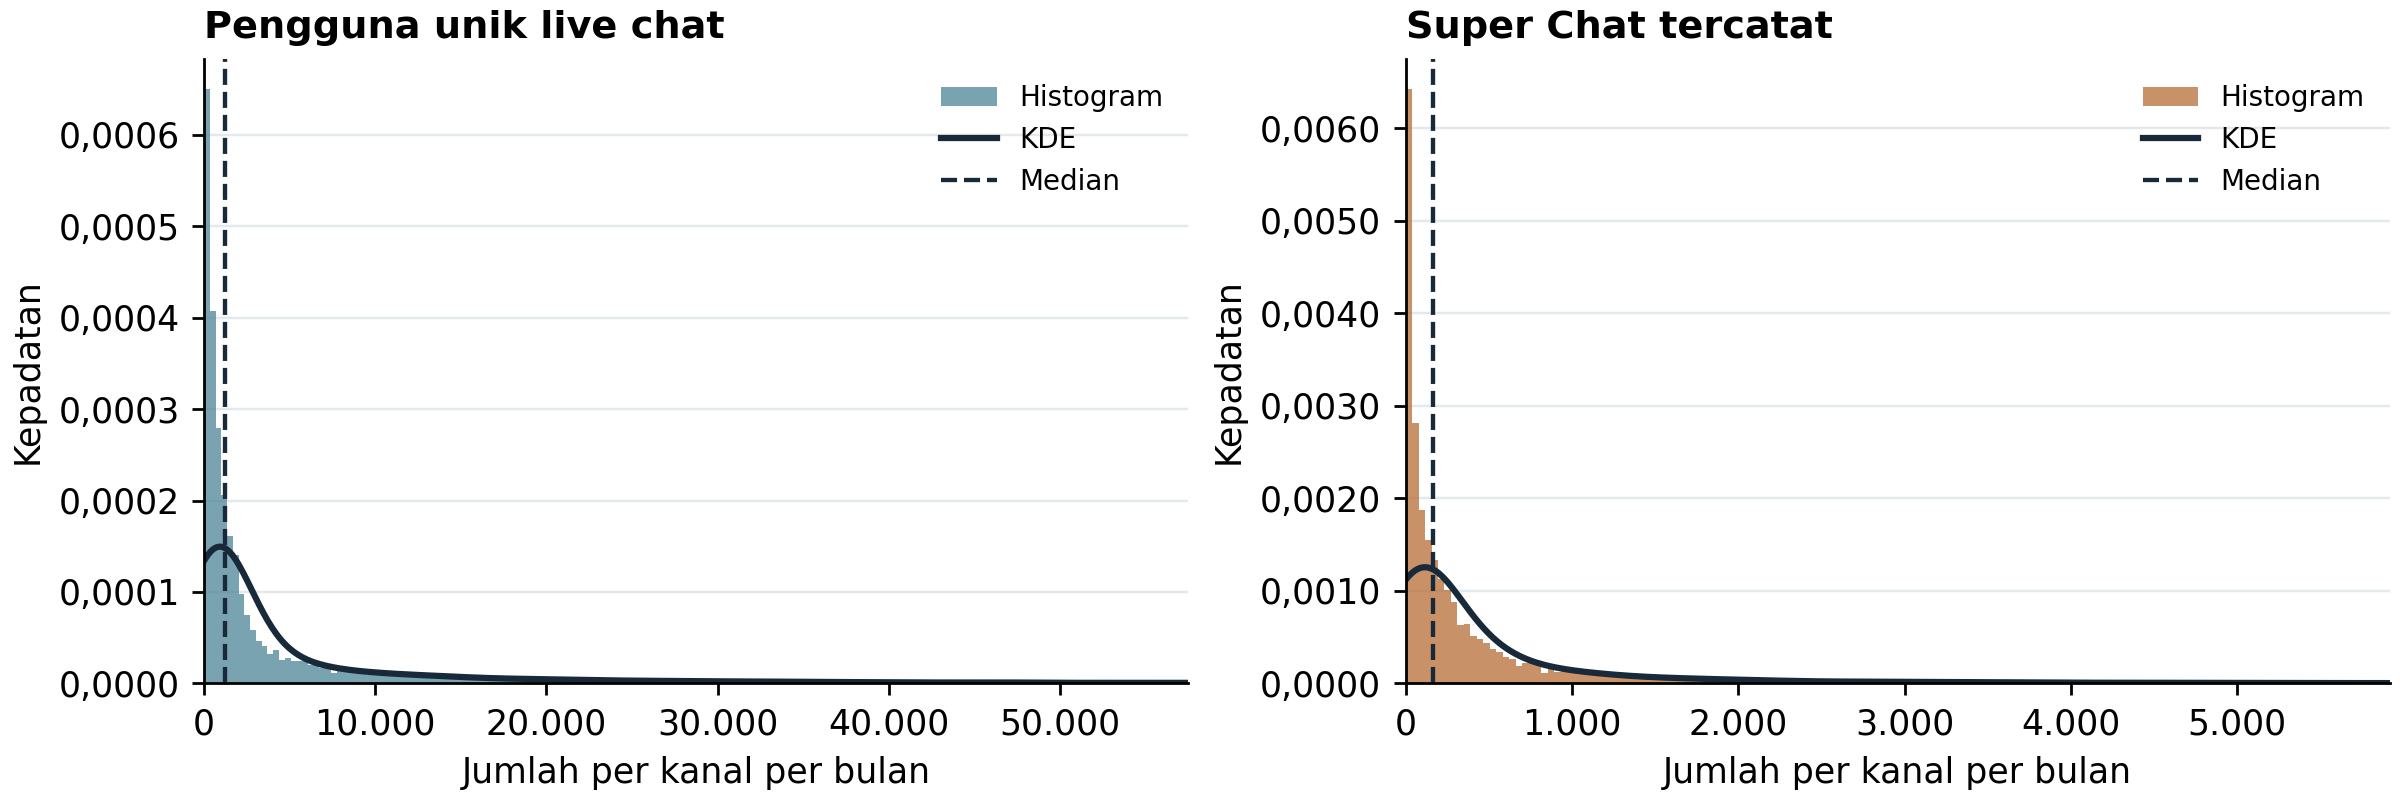

In [15]:
from matplotlib.ticker import FuncFormatter
from scipy.stats import gaussian_kde

warna_histogram = {
    "uniqueChatters": "#4A8396",
    "superChats": "#B66B34",
}
fig, axes = plt.subplots(1, 2, figsize=(9.6, 3.2), layout="constrained")

for ax, (kolom, judul) in zip(axes, nama_variabel.items()):
    nilai = numerik[kolom].dropna().to_numpy(dtype=float)
    p99 = np.quantile(nilai, 0.99)
    x = np.linspace(0, p99, 450)

    ax.hist(
        nilai, bins="fd", density=True, color=warna_histogram[kolom],
        alpha=0.74, label="Histogram",
    )
    ax.plot(x, gaussian_kde(nilai)(x), color="#182A3A", lw=1.8, label="KDE")
    ax.axvline(np.median(nilai), color="#182A3A", ls="--", lw=1.25, label="Median")
    ax.set_title(judul, loc="left", fontsize=11, fontweight="bold")
    ax.set(xlabel="Jumlah per kanal per bulan", ylabel="Kepadatan", xlim=(0, p99))
    ax.xaxis.set_major_formatter(
        FuncFormatter(lambda nilai, _: f"{nilai:,.0f}".replace(",", "."))
    )
    ax.yaxis.set_major_formatter(FuncFormatter(lambda nilai, _: f"{nilai:.4f}".replace(".", ",")))
    ax.spines[["top", "right"]].set_visible(False)
    ax.set_axisbelow(True)
    ax.grid(axis="y", color="#E3E9EC", lw=0.7)
    ax.legend(loc="upper right", frameon=False, fontsize=8)

simpan_gambar(fig, "Gambar_5_1_Histogram_KDE.png")

## Bab 6 — Transformasi data dan penyiapan fitur

### Perbandingan distribusi asli dan log1p

In [16]:
nama_variabel = {
    "uniqueChatters": "Pengguna unik live chat",
    "superChats": "Super Chat tercatat",
}
numerik = analysis[list(nama_variabel)].astype(float)
log_data = np.log1p(numerik)

tabel_6_1 = pd.DataFrame({
    "Skewness asli": numerik.skew(),
    "Skewness log1p": log_data.skew(),
    "Kurtosis berlebih asli": numerik.kurt(),
    "Kurtosis berlebih log1p": log_data.kurt(),
}).rename(index=nama_variabel).rename_axis("Variabel")
display(tabel_6_1.round(2))

,Skewness asli,Skewness log1p,Kurtosis berlebih asli,Kurtosis berlebih log1p
Variabel,,,,
Pengguna unik live chat,4.88,-0.12,37.60,0.11
Super Chat tercatat,10.61,-0.22,237.42,-0.34


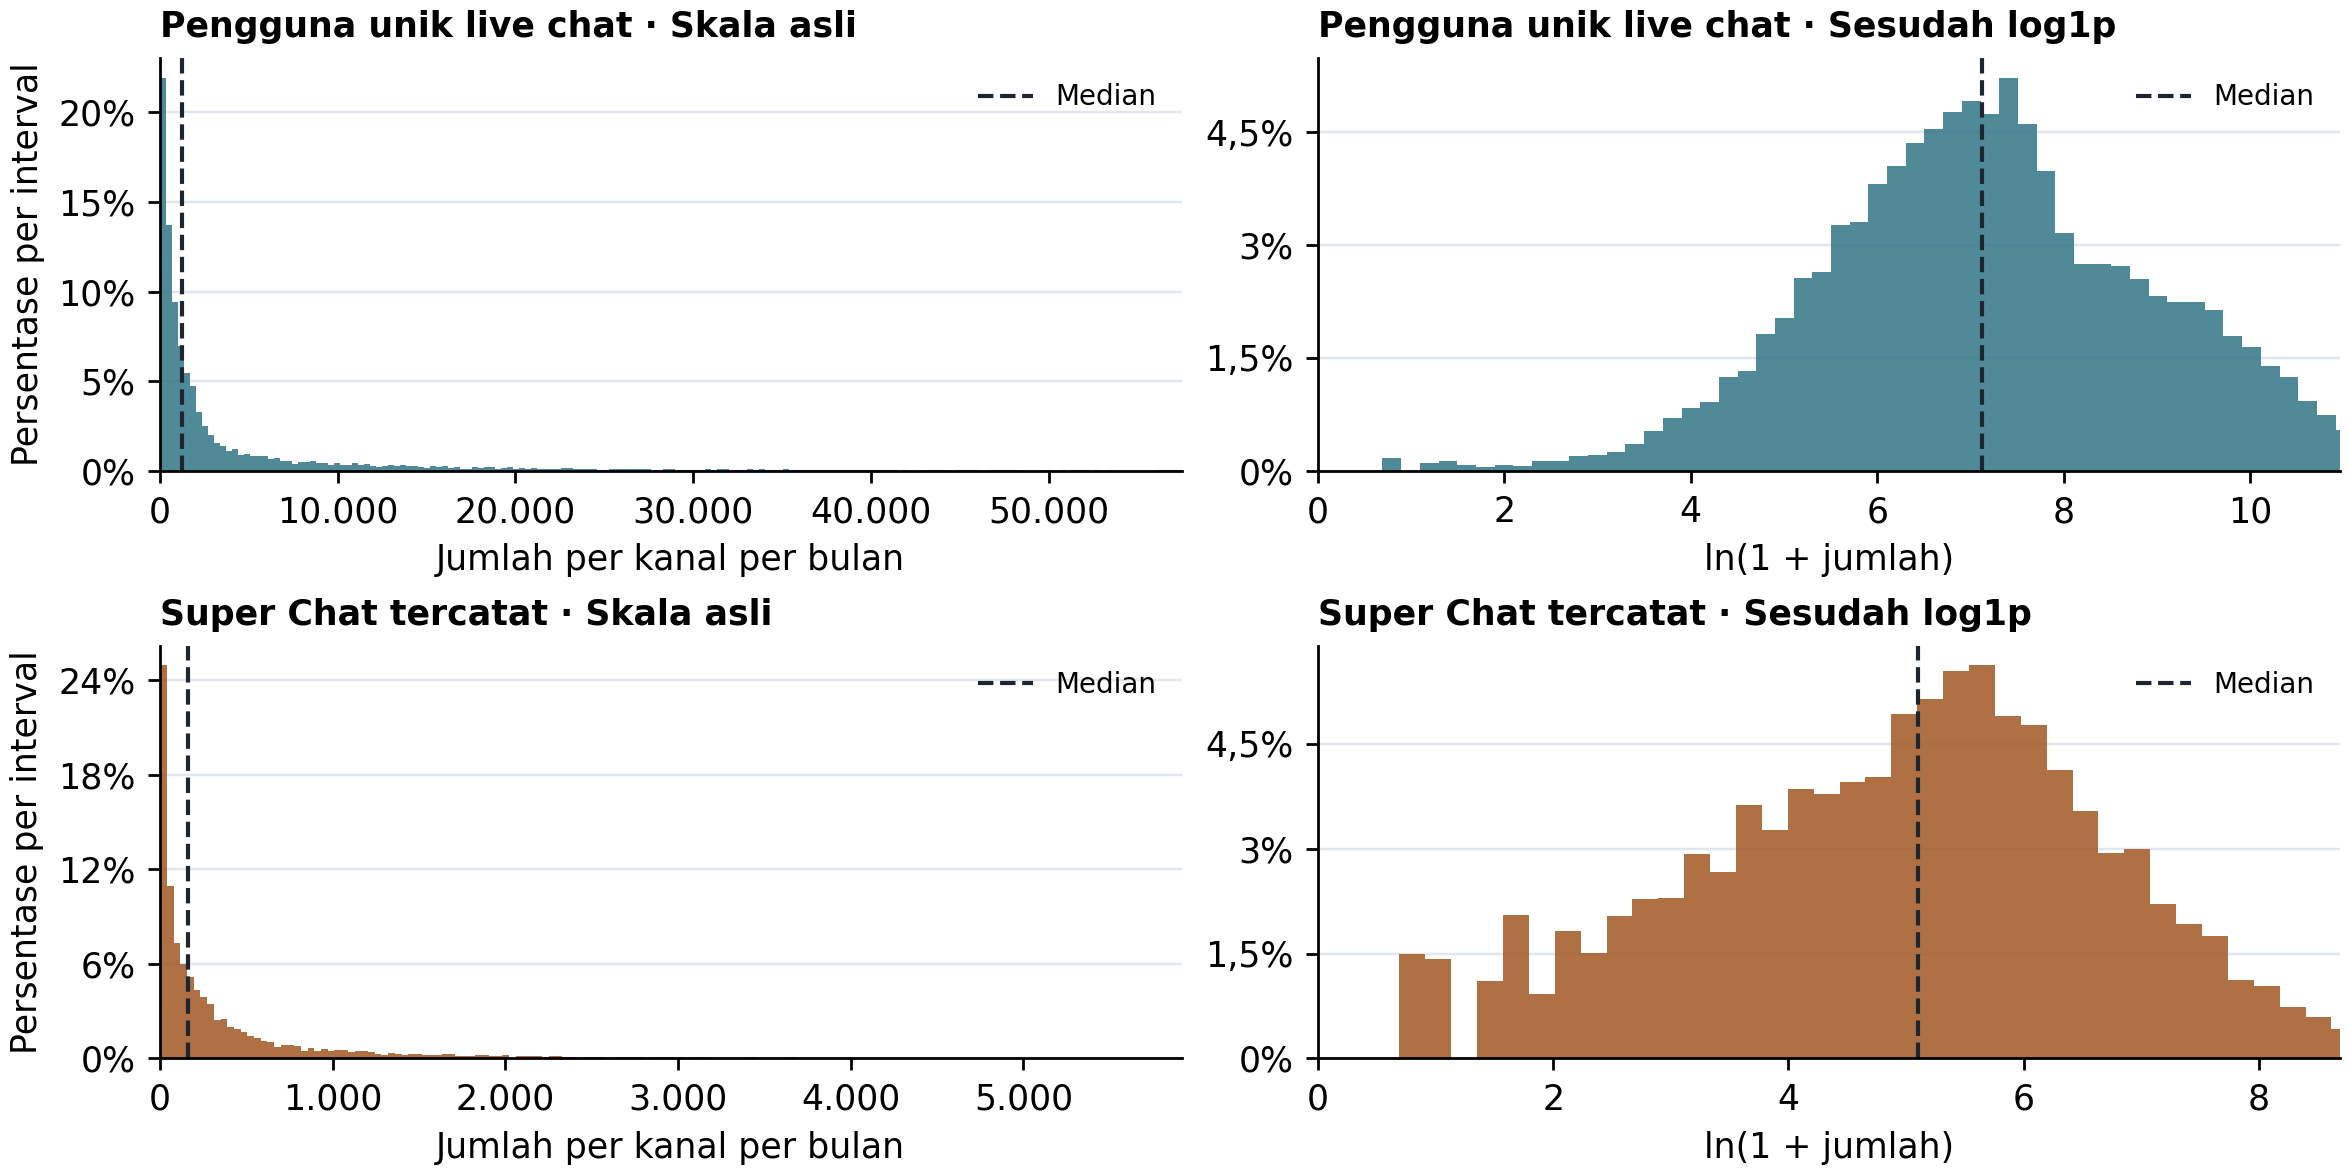

In [17]:
from matplotlib.ticker import FuncFormatter, MaxNLocator
from scipy.stats import gaussian_kde

def format_persen(nilai, _):
    teks = f"{100 * nilai:.1f}".removesuffix(".0")
    return teks.replace(".", ",") + "%"


warna = {"uniqueChatters": "#367789", "superChats": "#A35B28"}
fig, axes = plt.subplots(2, 2, figsize=(9.4, 4.7), layout="constrained")

for baris, (kolom, nama) in enumerate(nama_variabel.items()):
    asli = numerik[kolom].dropna().to_numpy()
    log = log_data[kolom].dropna().to_numpy()
    batas = np.quantile(asli, 0.99)
    panel = [
        (asli, batas, "Skala asli", "Jumlah per kanal per bulan"),
        (log, np.log1p(batas), "Sesudah log1p", "ln(1 + jumlah)"),
    ]

    for ax, (nilai, batas_kanan, judul, label_x) in zip(axes[baris], panel):
        tepi = np.histogram_bin_edges(nilai, bins="fd")
        ax.hist(
            nilai, bins=tepi, weights=np.full(len(nilai), 1 / len(nilai)),
            color=warna[kolom], alpha=0.87, edgecolor="none",
        )
        ax.axvline(np.median(nilai), color="#1D2630", ls="--", lw=1.2, label="Median")
        ax.set_title(f"{nama} · {judul}", loc="left", fontsize=10, fontweight="bold")
        ax.set(xlim=(0, batas_kanan), xlabel=label_x)
        ax.yaxis.set_major_formatter(FuncFormatter(format_persen))
        ax.yaxis.set_major_locator(MaxNLocator(5))
        ax.xaxis.set_major_locator(MaxNLocator(6, integer=True))
        ax.xaxis.set_major_formatter(
            FuncFormatter(lambda x, _: f"{x:,.0f}".replace(",", "."))
        )
        ax.spines[["top", "right"]].set_visible(False)
        ax.set_axisbelow(True)
        ax.grid(axis="y", color="#E1E7EC", lw=0.7)
        ax.legend(loc="upper right", frameon=False, fontsize=8)
    axes[baris, 0].set_ylabel("Persentase per interval")

simpan_gambar(fig, "Gambar_6_1_Transformasi_Log.png")

### Standardisasi dan normalisasi

In [18]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

scaler_standar = StandardScaler()
scaler_minmaks = MinMaxScaler()

standar = pd.DataFrame(
    scaler_standar.fit_transform(log_data),
    index=log_data.index, columns=log_data.columns,
)
minmaks = pd.DataFrame(
    scaler_minmaks.fit_transform(log_data),
    index=log_data.index, columns=log_data.columns,
)

def ringkas_skala(frame):
    return pd.DataFrame({
        "Rata-rata": frame.mean(),
        "Simpangan baku (ddof=0)": frame.std(ddof=0),
        "Minimum": frame.min(),
        "Maksimum": frame.max(),
    }).rename(index=nama_variabel)

tabel_6_2 = pd.concat({
    "StandardScaler": ringkas_skala(standar),
    "MinMaxScaler": ringkas_skala(minmaks),
}, names=["Metode", "Variabel"])
display(tabel_6_2.round(2) + 0.0)

jumlah_hilang = pd.DataFrame({
    "Skala asli": numerik.isna().sum(),
    "Sesudah log1p": log_data.isna().sum(),
    "StandardScaler": standar.isna().sum(),
    "MinMaxScaler": minmaks.isna().sum(),
}).rename(index=nama_variabel)
display(jumlah_hilang)

Rata-rata  ...  Maksimum
Metode         Variabel                            ...          
StandardScaler Pengguna unik live chat       0.00  ...      2.88
               Super Chat tercatat           0.00  ...      3.30
MinMaxScaler   Pengguna unik live chat       0.56  ...      1.00
               Super Chat tercatat           0.42  ...      1.00

[4 rows x 4 columns]

,Skala asli,Sesudah log1p,StandardScaler,MinMaxScaler
Pengguna unik live chat,0,0,0,0
Super Chat tercatat,1527,1527,1527,1527


### One-hot encoding afiliasi

Label afiliasi yang belum diketahui mendapat indikatornya sendiri.
Untuk pemodelan, tetapkan kategori menggunakan data latih.

In [19]:
indikator_afiliasi = pd.get_dummies(afiliasi_tampilan, dtype="int8")
assert indikator_afiliasi.sum(axis=1).eq(1).all()
print(f"{angka_id(len(indikator_afiliasi))} pengamatan, {indikator_afiliasi.shape[1]} indikator afiliasi.")
display(
    indikator_afiliasi.sum()
    .reindex(["Independents", "Hololive", "Tidak diketahui"], fill_value=0)
    .rename("Jumlah indikator bernilai 1")
    .rename_axis("Kategori")
    .to_frame()
)

12.468 pengamatan, 61 indikator afiliasi.


,Jumlah indikator bernilai 1
Kategori,
Independents,4139
Hololive,1076
Tidak diketahui,28


### Fitur bulan berjalan dan target bulan berikutnya

Intensitas percakapan dihitung dari pesan per pengguna unik. Target
dicocokkan ke bulan kalender berikutnya untuk kanal yang sama dalam
tabel analisis. Pengamatan tanpa padanan target mempertahankan nilai
kosong. Hitungan Super Chat bulan berjalan disiapkan sebagai prediksi
acuan.

In [20]:
kolom_fitur = kunci + ["chats", "uniqueChatters", "superChats"]
fitur_bulanan = analysis.loc[analysis["period"].lt(akhir), kolom_fitur].copy()
pengguna_positif = fitur_bulanan["uniqueChatters"].where(fitur_bulanan["uniqueChatters"].gt(0))
fitur_bulanan["pesan_per_pengguna"] = fitur_bulanan["chats"].div(pengguna_positif)
fitur_bulanan["log1p_pengguna_unik"] = log_data.loc[fitur_bulanan.index, "uniqueChatters"]
fitur_bulanan["bulan_target"] = fitur_bulanan["period"] + 1

nama_target = "superChats_bulan_berikutnya"
target = analysis[kunci + ["superChats"]].rename(
    columns={"period": "bulan_target", "superChats": nama_target}
)
data_model = fitur_bulanan.merge(
    target,
    on=["channelId", "bulan_target"],
    how="left",
    validate="one_to_one",
)
ringkasan_target = pd.Series({
    "Bulan target dalam rentang dataset": len(data_model),
    "Target Super Chat bulan berikutnya tercatat": data_model[nama_target].notna().sum(),
    "Target dan Super Chat bulan berjalan tercatat": data_model[["superChats", nama_target]].notna().all(axis=1).sum(),
}, name="Jumlah pengamatan")
display(ringkasan_target.to_frame())

,Jumlah pengamatan
Bulan target dalam rentang dataset,11446
Target Super Chat bulan berikutnya tercatat,9858
Target dan Super Chat bulan berjalan tercatat,9517


## Bab 7 — Visualisasi dan hubungan antarvariabel

### Distribusi variabel numerik dan kategori afiliasi

,Pengguna unik live chat,Super Chat tercatat
count,12468.0,10941.0
min,1.0,1.0
50%,1241.0,163.0
max,224155.0,49855.0


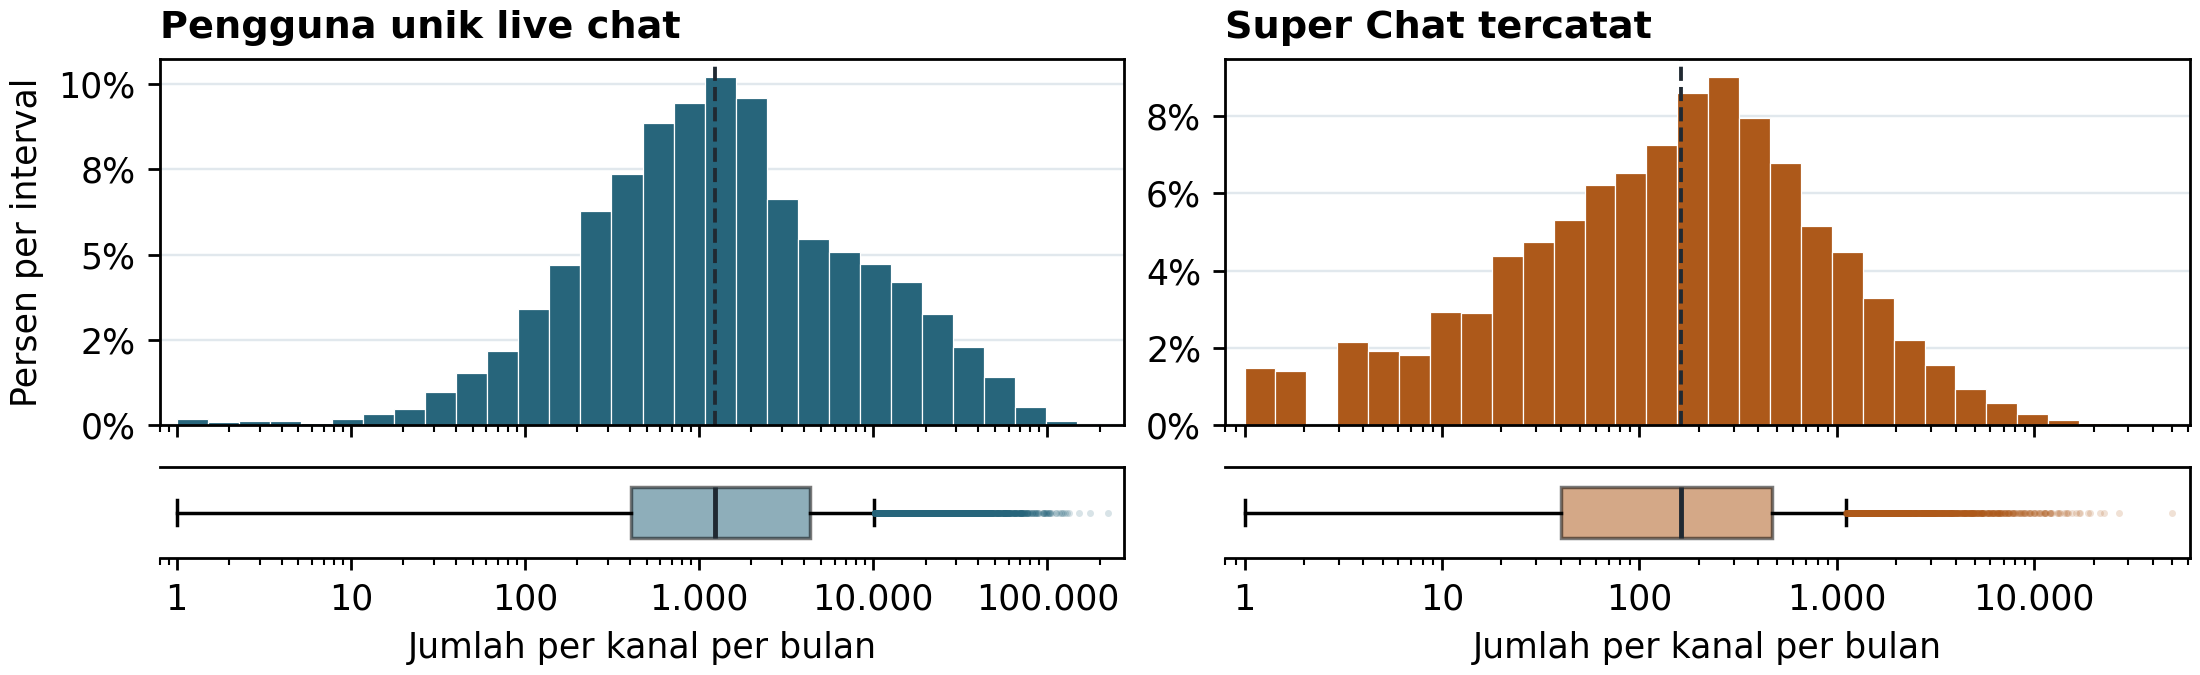

In [21]:
biru = "#27657b"
jingga = "#ad591a"

label_numerik = {"uniqueChatters": "Pengguna unik live chat", "superChats": "Super Chat tercatat"}
ringkasan_numerik = analysis[list(label_numerik)].describe().loc[["count", "min", "50%", "max"]]
display(ringkasan_numerik.rename(columns=label_numerik))
fig, axes = plt.subplots(2, 2, figsize=(8.8, 2.7), sharex="col",
                         gridspec_kw={"height_ratios": [4, 1]}, layout="constrained")
for indeks, ((kolom, label), warna) in enumerate(zip(label_numerik.items(), (biru, jingga))):
    nilai = analysis[kolom].dropna().to_numpy(dtype=float)
    histogram, box = axes[:, indeks]
    tepi = np.geomspace(nilai.min(), nilai.max(), num=31)
    histogram.hist(nilai, bins=tepi, weights=np.full(len(nilai), 1 / len(nilai)),
                   color=warna, edgecolor="white", linewidth=0.35)
    histogram.set_title(label, loc="left", fontweight="bold", fontsize=11)
    histogram.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    histogram.axvline(np.median(nilai), color="#202932", linestyle="--", linewidth=1.1)
    histogram.set_axisbelow(True)
    histogram.grid(axis="y", color="#E1E8ED", linewidth=0.7)
    box.boxplot(nilai, orientation="horizontal", widths=0.55, whis=1.5, patch_artist=True,
                boxprops={"facecolor": warna, "alpha": 0.52},
                medianprops={"color": "#202932", "linewidth": 1.4},
                flierprops={"marker": ".", "markersize": 2, "alpha": 0.18, "markeredgecolor": warna})
    box.set(xscale="log", xlim=(0.8, nilai.max() * 1.23), yticks=[], xlabel="Jumlah per kanal per bulan")
    box.spines["left"].set_visible(False)
    format_log(box.xaxis)
axes[0, 0].set_ylabel("Persen per interval")
simpan_gambar(fig, "Gambar_7_1_Distribusi_Numerik.png")

,Pengamatan,Persentase
Independents,4139,33.20
Nijisanji,2613,20.96
Hololive,1076,8.63
774inc,435,3.49
ReAcT,326,2.61
Afiliasi lainnya,3851,30.89
Tidak diketahui,28,0.22


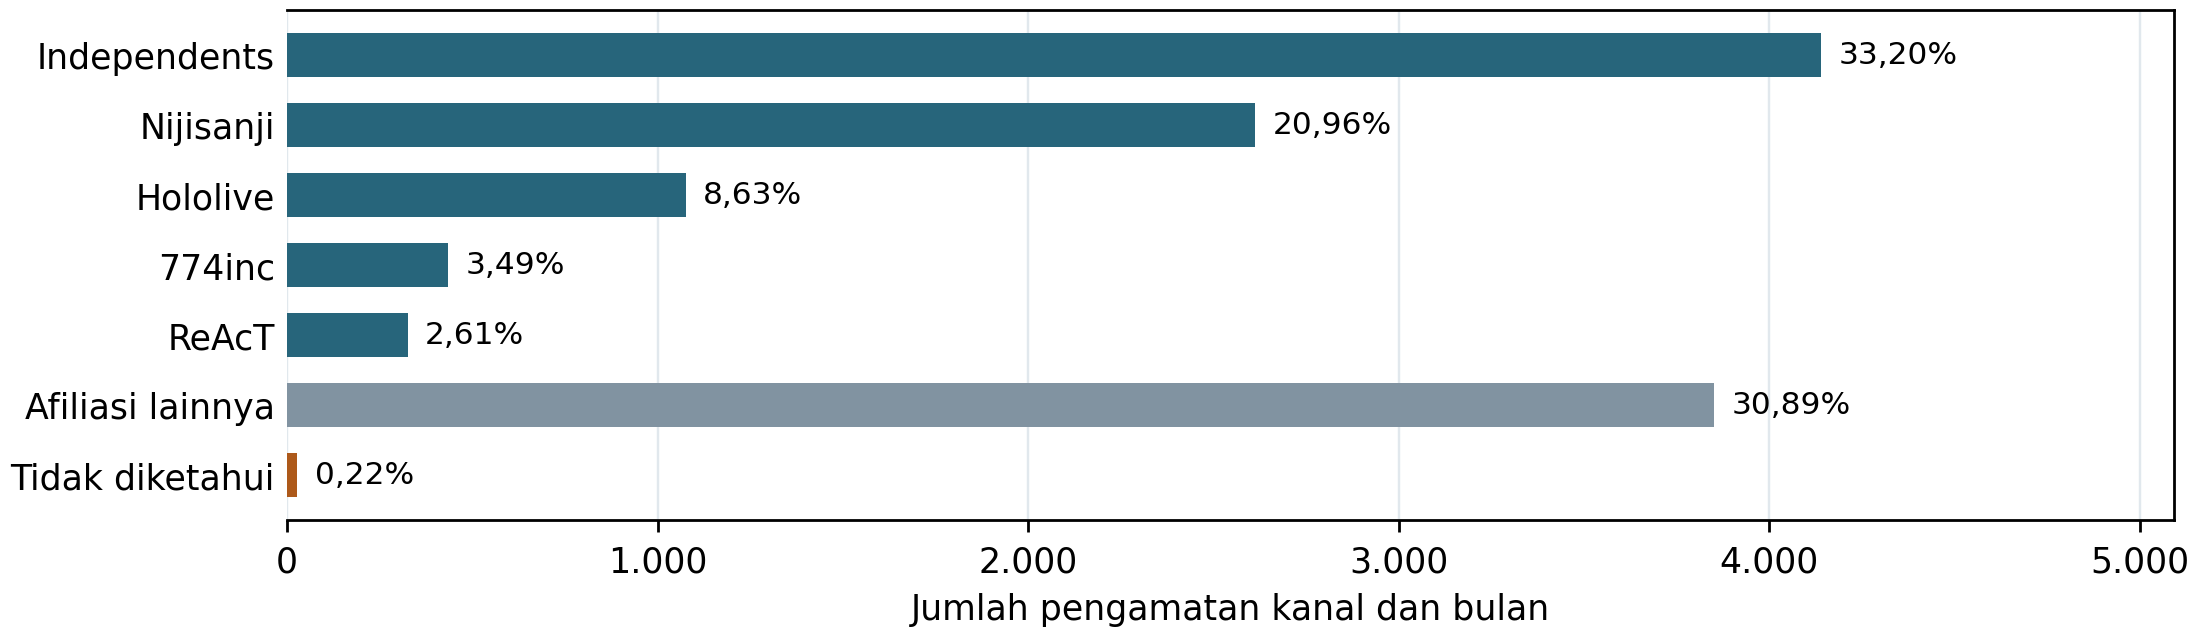

In [22]:
frekuensi = analysis["affiliation"].value_counts()
afiliasi_utama = frekuensi.head(5).index.tolist()
jumlah_hilang_afiliasi = int(analysis["affiliation"].isna().sum())
frekuensi_grafik = pd.concat([
    frekuensi.loc[afiliasi_utama],
    pd.Series({"Afiliasi lainnya": frekuensi.iloc[5:].sum(),
               "Tidak diketahui": jumlah_hilang_afiliasi}),
])
ringkasan_afiliasi = pd.DataFrame({
    "Pengamatan": frekuensi_grafik,
    "Persentase": 100 * frekuensi_grafik / len(analysis),
})
display(ringkasan_afiliasi.round(2))
fig, ax = plt.subplots(figsize=(8.8, 2.55), layout="constrained")
batang = ax.barh(frekuensi_grafik.index, frekuensi_grafik.to_numpy(), height=0.63,
                 color=[biru] * len(afiliasi_utama) + ["#8193A1", jingga])
labels = [f"{angka_id(persen, 2)}%" for persen in ringkasan_afiliasi["Persentase"]]
ax.bar_label(batang, labels=labels, padding=5, fontsize=9)
ax.set(xlabel="Jumlah pengamatan kanal dan bulan",
       xlim=(0, frekuensi_grafik.max() * 1.23))
ax.xaxis.set_major_formatter(FuncFormatter(lambda nilai, _: angka_id(nilai)))
ax.invert_yaxis()
ax.set_axisbelow(True)
ax.grid(axis="x", color="#E1E8ED", linewidth=0.7)
ax.spines["left"].set_visible(False)
ax.tick_params(axis="y", length=0)
simpan_gambar(fig, "Gambar_7_2_Frekuensi_Afiliasi.png")

### Pengguna unik, Super Chat, dan afiliasi

,jumlah,median_pengguna,median_super_chat
uniqueChatters,,,
Q1,2745,240.0,27.0
Q2,2727,855.0,109.0
Q3,2734,2310.0,231.0
Q4,2735,13129.0,770.0


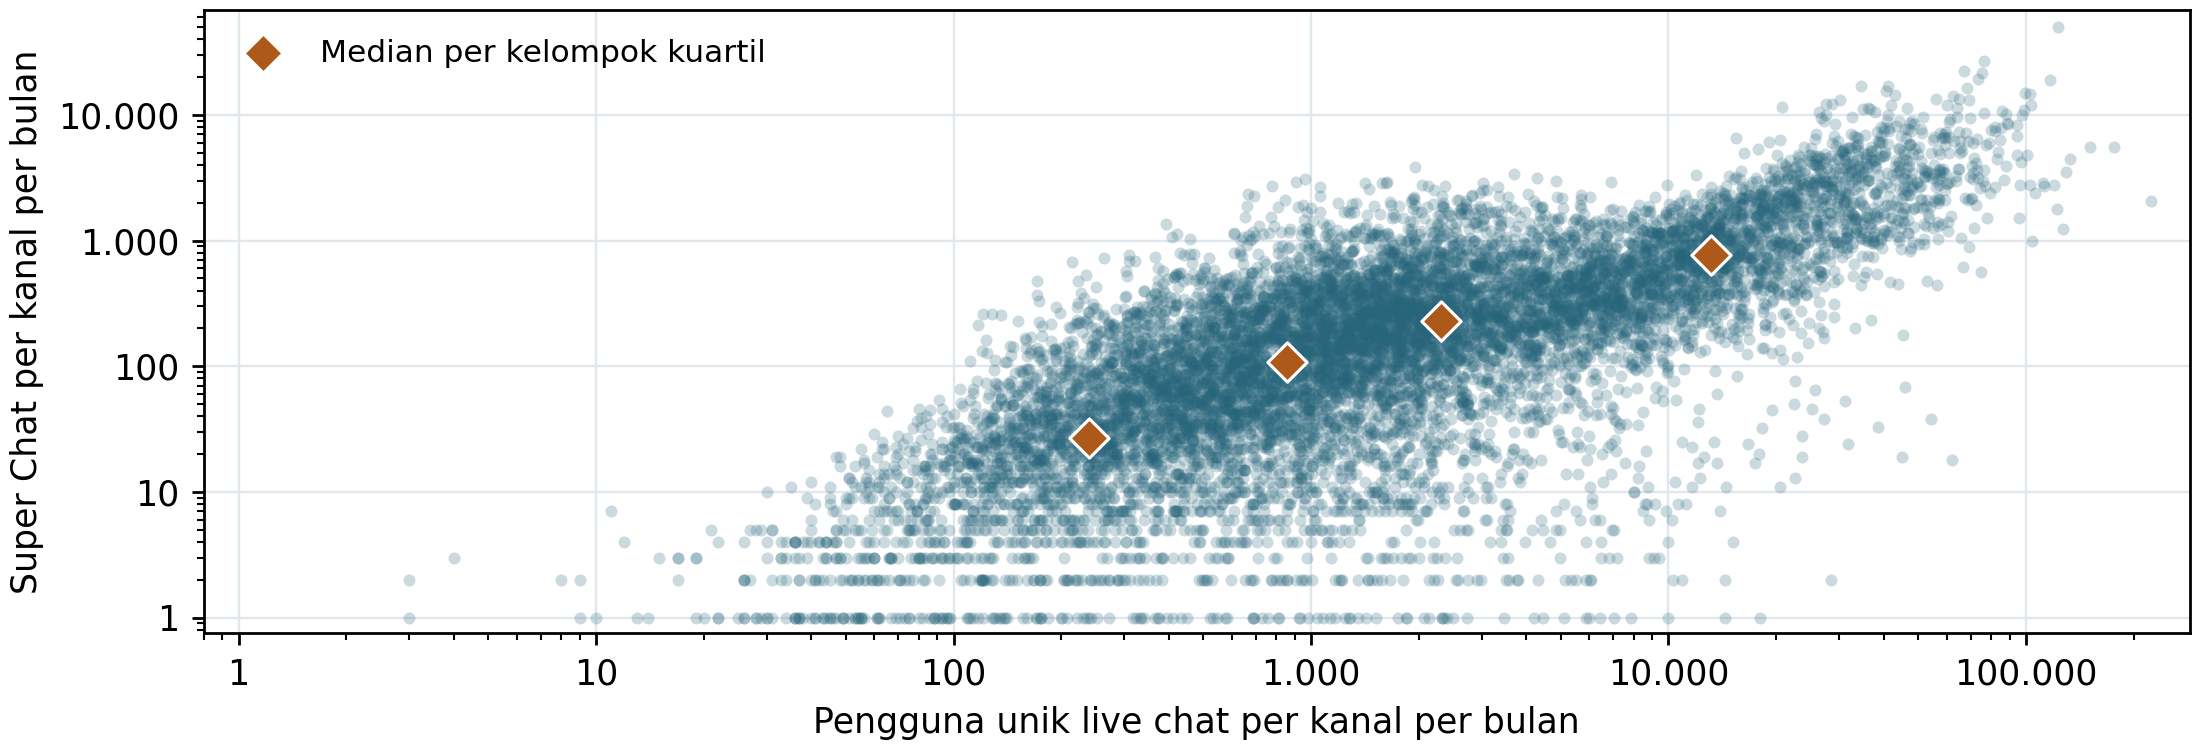

In [23]:
pasangan = matched
kuartil = pd.qcut(pasangan["uniqueChatters"], 4, labels=["Q1", "Q2", "Q3", "Q4"])
median_kuartil = pasangan.groupby(kuartil, observed=True).agg(
    jumlah=("superChats", "size"), median_pengguna=("uniqueChatters", "median"),
    median_super_chat=("superChats", "median"),
)
display(median_kuartil)
fig, ax = plt.subplots(figsize=(8.8, 3.0), layout="constrained")
ax.scatter(pasangan["uniqueChatters"], pasangan["superChats"],
           s=12, alpha=0.24, color=biru, linewidths=0)
ax.scatter(median_kuartil["median_pengguna"], median_kuartil["median_super_chat"],
           s=64, marker="D", color=jingga, edgecolor="white", linewidth=0.9,
           zorder=3, label="Median per kelompok kuartil")
ax.set(xscale="log", yscale="log", xlim=(0.8, pasangan.uniqueChatters.max() * 1.28),
       ylim=(0.75, pasangan.superChats.max() * 1.36),
       xlabel="Pengguna unik live chat per kanal per bulan",
       ylabel="Super Chat per kanal per bulan")
format_log(ax.xaxis)
format_log(ax.yaxis)
ax.set_axisbelow(True)
ax.grid(color="#E1E8ED", linewidth=0.7)
ax.legend(loc="upper left", frameon=False, fontsize=9)
simpan_gambar(fig, "Gambar_7_3_Diagram_Pencar.png")

,jumlah,median,q1,q3
affiliation,,,,
Independents,3647,71.0,21.0,218.00
Nijisanji,2466,243.0,64.0,669.75
Hololive,1000,1343.0,517.0,3013.50
774inc,411,255.0,133.5,445.50
ReAcT,297,81.0,27.0,218.00


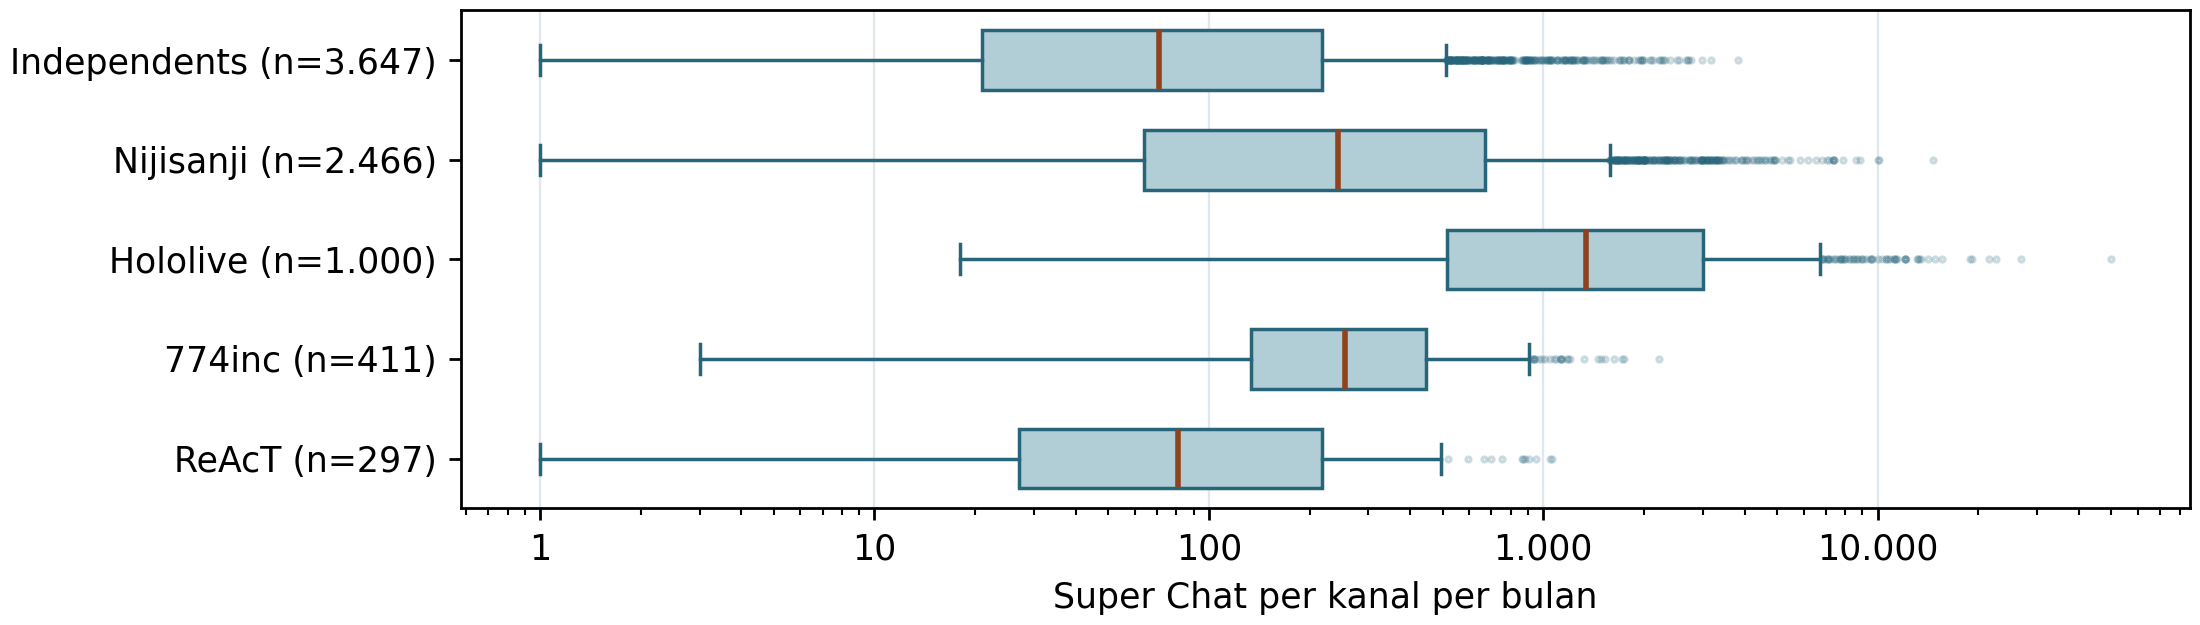

In [24]:
data_boxplot = analysis.loc[
    analysis["affiliation"].isin(afiliasi_utama) & analysis["superChats"].notna(),
    ["affiliation", "superChats"],
]
ringkasan_boxplot = data_boxplot.groupby("affiliation", observed=True)["superChats"].agg(
    jumlah="size", median="median", q1=lambda kolom: kolom.quantile(0.25),
    q3=lambda kolom: kolom.quantile(0.75),
).reindex(afiliasi_utama)
display(ringkasan_boxplot)
kelompok = [data_boxplot.loc[data_boxplot["affiliation"].eq(nama), "superChats"].to_numpy(dtype=float)
            for nama in afiliasi_utama]
fig, ax = plt.subplots(figsize=(8.8, 2.5), layout="constrained")
ax.boxplot(kelompok, orientation="horizontal", whis=1.5, widths=0.6, patch_artist=True,
           boxprops={"facecolor": "#B1CDD6", "edgecolor": biru},
           whiskerprops={"color": biru}, capprops={"color": biru},
           medianprops={"color": "#8F421D", "linewidth": 1.6},
           flierprops={"marker": ".", "markersize": 2.7, "alpha": 0.24, "markeredgecolor": biru})
ylabels = [f"{nama} (n={angka_id(jumlah)})" for nama, jumlah in ringkasan_boxplot["jumlah"].items()]
ax.set_yticks(range(1, len(ylabels) + 1), labels=ylabels)
ax.set(xscale="log", xlabel="Super Chat per kanal per bulan")
ax.invert_yaxis()
format_log(ax.xaxis)
ax.set_axisbelow(True)
ax.grid(axis="x", color="#E1E8ED", linewidth=0.7)
simpan_gambar(fig, "Gambar_7_4_Boxplot_Afiliasi.png")

### Matriks korelasi Spearman

Jumlah pengamatan untuk seluruh matriks = 10.941


,Pesan live chat,Pengguna unik live chat,Super Chat,Pengirim unik Super Chat
Pesan live chat,1.000,0.912,0.831,0.852
Pengguna unik live chat,0.912,1.000,0.723,0.798
Super Chat,0.831,0.723,1.000,0.961
Pengirim unik Super Chat,0.852,0.798,0.961,1.000


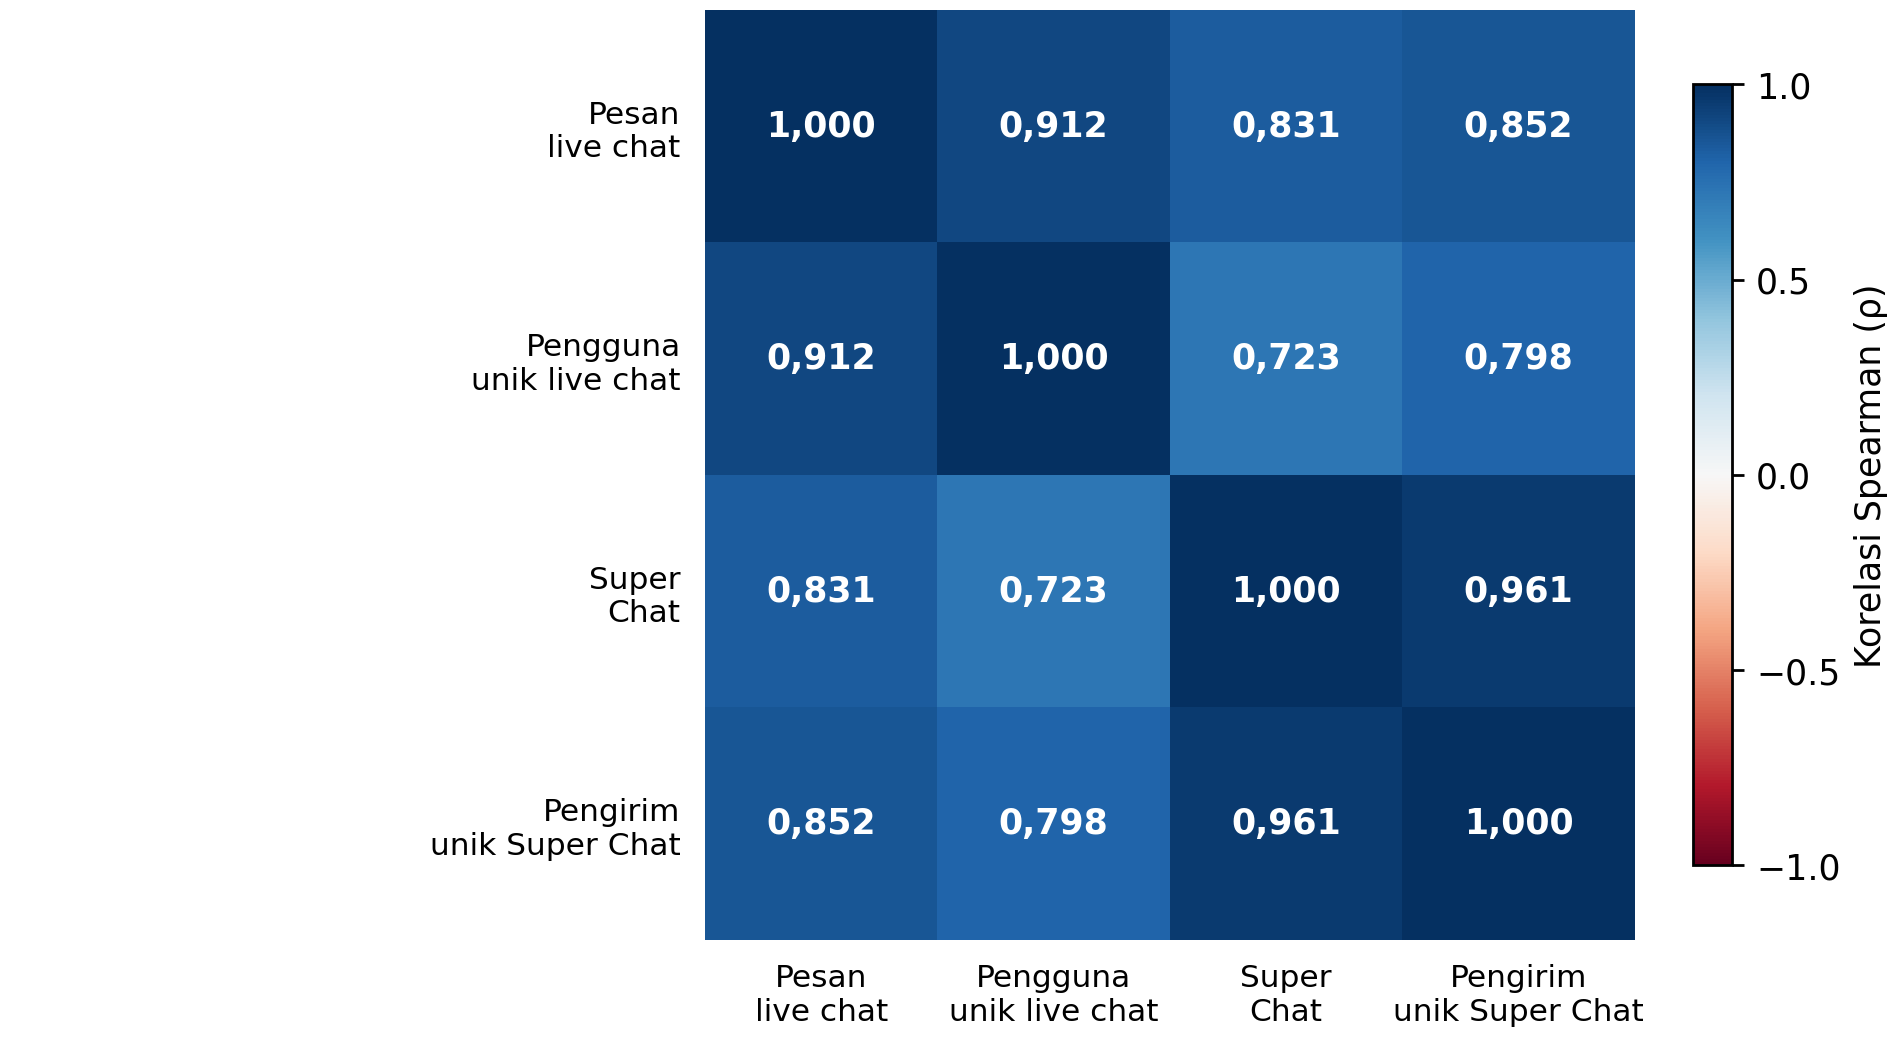

In [25]:
label_korelasi = {"chats": "Pesan live chat", "uniqueChatters": "Pengguna unik live chat",
                  "superChats": "Super Chat", "uniqueSuperChatters": "Pengirim unik Super Chat"}
data_korelasi = analysis[list(label_korelasi)].dropna()
korelasi = data_korelasi.corr(method="spearman")
print(f"Jumlah pengamatan untuk seluruh matriks = {angka_id(len(data_korelasi))}")
display(korelasi.rename(index=label_korelasi, columns=label_korelasi).round(3))
fig, ax = plt.subplots(figsize=(7.6, 4.15), layout="constrained")
heatmap = ax.imshow(korelasi, cmap="RdBu", vmin=-1, vmax=1)
labels = ["Pesan\nlive chat", "Pengguna\nunik live chat", "Super\nChat", "Pengirim\nunik Super Chat"]
ax.set_xticks(range(4), labels=labels)
ax.set_yticks(range(4), labels=labels)
ax.tick_params(length=0, pad=7, labelsize=9)
for baris in range(4):
    for kolom in range(4):
        nilai = korelasi.iloc[baris, kolom]
        ax.text(kolom, baris, angka_id(nilai, 3), ha="center", va="center",
                color="white" if abs(nilai) > 0.60 else "#172A38", fontweight="bold")
ax.spines[:].set_visible(False)
bar = fig.colorbar(heatmap, ax=ax, shrink=0.84, pad=0.03, ticks=[-1, -0.5, 0, 0.5, 1])
bar.set_label("Korelasi Spearman (ρ)")
simpan_gambar(fig, "Gambar_7_5_Heatmap_Spearman.png")

### Korelasi Spearman per bulan

Setiap baris merangkum hubungan antarkanal dalam satu bulan. Cakupan
Super Chat Maret 2021 bersifat parsial karena pencatatan dimulai pada
tanggal 16. Tabel kedua mengukur perubahan korelasi gabungan ketika
bulan tersebut dikeluarkan.

In [26]:
def ringkas_korelasi(pasangan):
    return {
        "Pasangan": len(pasangan),
        "Spearman": pasangan["uniqueChatters"].corr(
            pasangan["superChats"], method="spearman"
        ),
    }

tabel_bulanan = pd.DataFrame(
    [
        {"Bulan": bulan, **ringkas_korelasi(pasangan_bulan)}
        for bulan, pasangan_bulan in matched.groupby("period", sort=True)
    ]
).set_index("Bulan")
display(tabel_bulanan.round(3))

tanpa_maret = matched.loc[matched["period"].ne(pd.Period("2021-03", freq="M"))]
tabel_cakupan_maret = pd.DataFrame.from_dict({
    "Semua bulan": ringkas_korelasi(matched),
    "Tanpa Maret 2021": ringkas_korelasi(tanpa_maret),
}, orient="index").rename_axis("Cakupan")
display(tabel_cakupan_maret.round(3))

,Pasangan,Spearman
Bulan,,
2021-03,321,0.789
2021-04,367,0.784
2021-05,411,0.784
2021-06,459,0.769
2021-07,518,0.732
2021-08,617,0.748
2021-09,660,0.716
2021-10,684,0.708
2021-11,697,0.713


,Pasangan,Spearman
Cakupan,,
Semua bulan,10941,0.723
Tanpa Maret 2021,10620,0.725


## Bab 8 — Deteksi pencilan dan uji sensitivitas

### Ambang IQR dan Z-score

In [27]:
label_variabel = {
    "uniqueChatters": "Pengguna unik live chat",
    "superChats": "Super Chat tercatat",
}
numerik = analysis[list(label_variabel)].astype(float)
q1 = numerik.quantile(0.25)
q3 = numerik.quantile(0.75)
iqr = q3 - q1
bawah_iqr, atas_iqr = q1 - 1.5 * iqr, q3 + 1.5 * iqr

rerata = numerik.mean()
simpangan = numerik.std(ddof=0)
z_score = (numerik - rerata) / simpangan
bawah_z, atas_z = rerata - 3 * simpangan, rerata + 3 * simpangan

pencilan_iqr = (numerik.lt(bawah_iqr) | numerik.gt(atas_iqr)).astype("boolean")
pencilan_iqr = pencilan_iqr.where(numerik.notna())
pencilan_z = z_score.abs().gt(3).astype("boolean").where(numerik.notna())

def ringkas_deteksi(batas_bawah, batas_atas, penanda):
    jumlah = penanda.sum()
    return pd.DataFrame({
        "Jumlah teramati": numerik.count(),
        "Batas bawah": batas_bawah,
        "Batas atas": batas_atas,
        "Jumlah pencilan": jumlah,
        "Persentase pencilan": 100 * jumlah / numerik.count(),
    }).rename_axis("Kolom")

tabel_8_1 = pd.concat({
    "IQR": ringkas_deteksi(bawah_iqr, atas_iqr, pencilan_iqr),
    "Z-score": ringkas_deteksi(bawah_z, atas_z, pencilan_z),
}, names=["Metode"]).reorder_levels(["Kolom", "Metode"]).sort_index()
display(tabel_8_1.rename(index=label_variabel, level="Kolom").round(2))

irisan_metode = pd.DataFrame({
    "IQR saja": (pencilan_iqr & ~pencilan_z).sum(),
    "Z-score saja": (pencilan_z & ~pencilan_iqr).sum(),
    "Keduanya": (pencilan_iqr & pencilan_z).sum(),
})
display(irisan_metode.rename(index=label_variabel))

Jumlah teramati  ...  Persentase pencilan
Kolom                   Metode                    ...                     
Super Chat tercatat     IQR                10941  ...                11.33
                        Z-score            10941  ...                 1.68
Pengguna unik live chat IQR                12468  ...                14.37
                        Z-score            12468  ...                  2.4

[4 rows x 5 columns]

,IQR saja,Z-score saja,Keduanya
Pengguna unik live chat,1493,0,299
Super Chat tercatat,1056,0,184


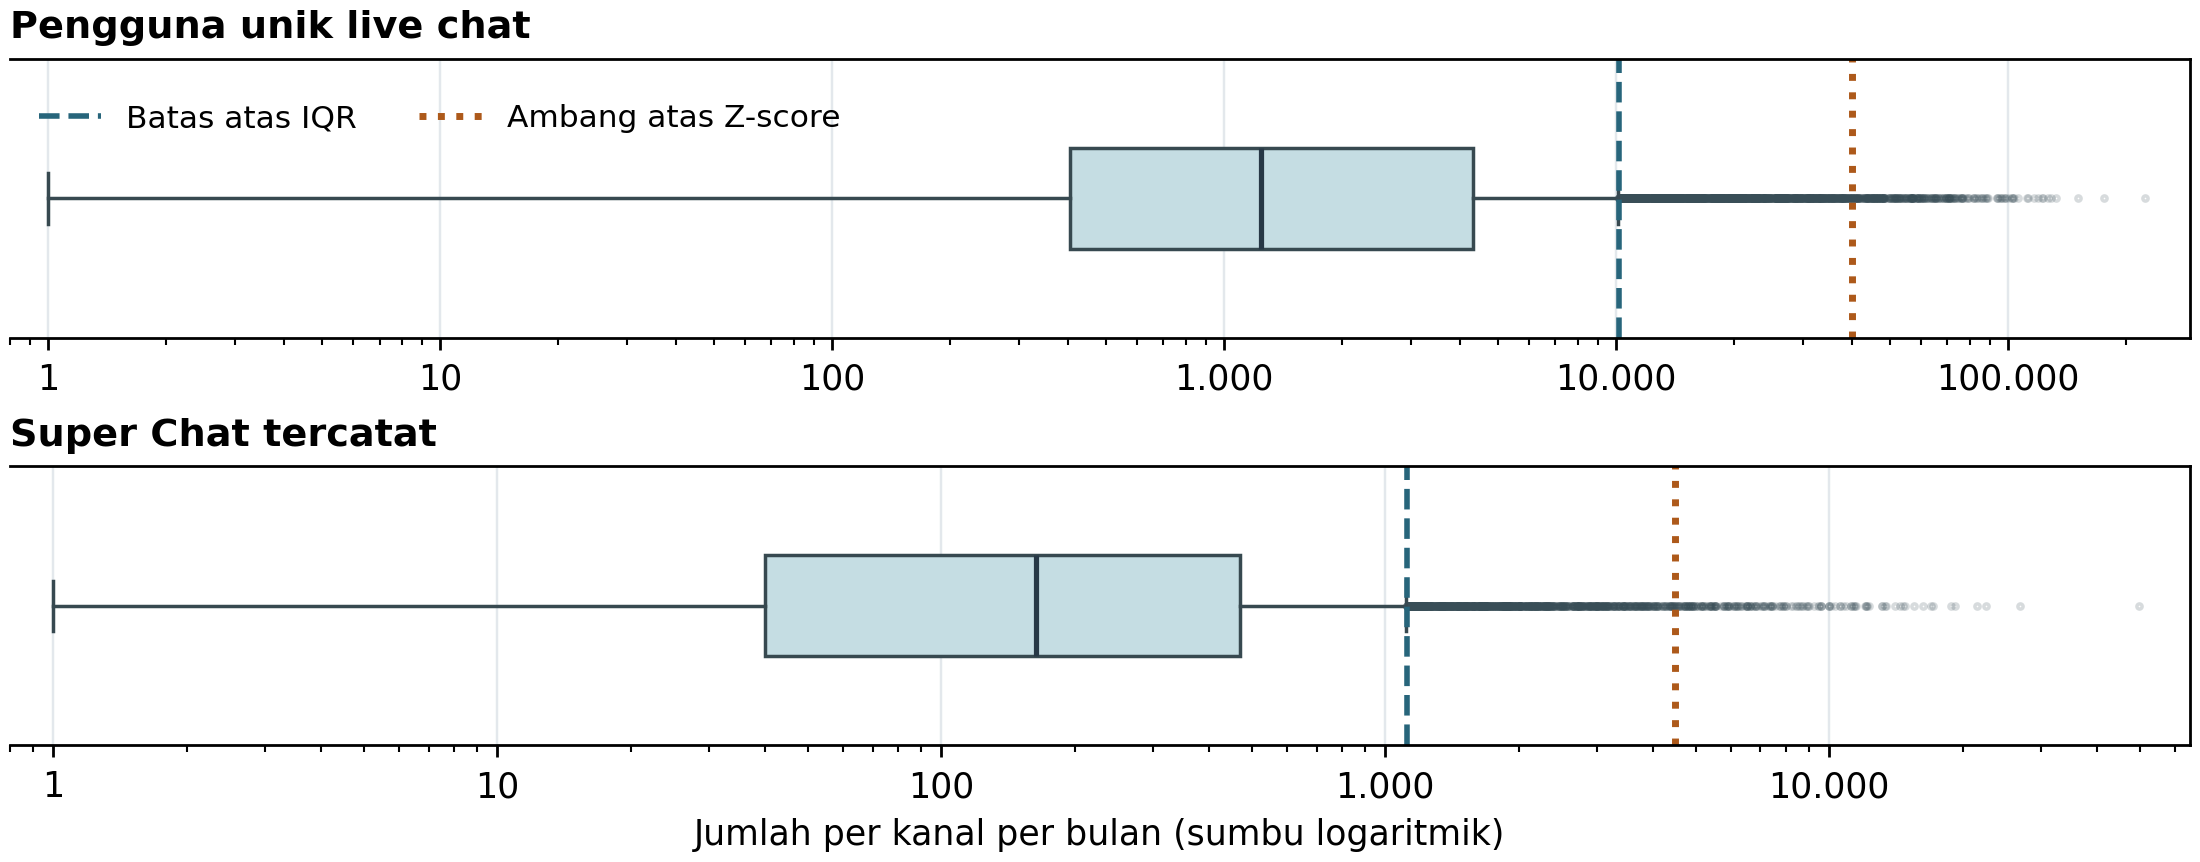

In [28]:
fig, axes = plt.subplots(2, 1, figsize=(8.8, 3.45), layout="constrained")

for ax, (kolom, judul) in zip(axes, label_variabel.items()):
    nilai = numerik[kolom].dropna().to_numpy()
    ax.boxplot(
        nilai, orientation="horizontal", widths=0.36, whis=1.5, patch_artist=True,
        boxprops={"facecolor": "#C5DDE3", "edgecolor": "#374950"},
        whiskerprops={"color": "#374950"},
        capprops={"color": "#374950"},
        medianprops={"color": "#273846", "linewidth": 1.5},
        flierprops={"marker": ".", "markersize": 3, "markeredgecolor": "#394E57", "alpha": 0.20},
    )
    ax.axvline(atas_iqr[kolom], color=biru, linestyle="--", linewidth=1.6, label="Batas atas IQR")
    ax.axvline(atas_z[kolom], color=jingga, linestyle=":", linewidth=2.0, label="Ambang atas Z-score")
    ax.set(xscale="log", yticks=[], xlim=(0.8, nilai.max() * 1.3))
    ax.set_title(judul, fontweight="bold", loc="left", fontsize=11)
    ax.spines["left"].set_visible(False)
    ax.set_axisbelow(True)
    ax.grid(axis="x", color="#E3E8EC", linewidth=0.7)
    format_log(ax.xaxis)

axes[0].legend(loc="upper left", bbox_to_anchor=(0.0, 0.94), ncols=2, frameon=False, fontsize=9)
axes[-1].set_xlabel("Jumlah per kanal per bulan (sumbu logaritmik)")
simpan_gambar(fig, "Gambar_8_1_Deteksi_Pencilan.png")

### Pemeriksaan konsistensi dan pencocokan nilai maksimum

In [29]:
ditandai = pencilan_iqr.any(axis=1) | pencilan_z.any(axis=1)
audit = analysis.loc[ditandai]
cek_konsistensi = pd.Series({
    "Baris kanal dan bulan yang ditandai": len(audit),
    "Pengguna unik melebihi jumlah pesan live chat": audit["uniqueChatters"].gt(audit["chats"]).sum(),
    "Pengirim unik Super Chat melebihi jumlah Super Chat": audit["uniqueSuperChatters"].gt(audit["superChats"]).sum(),
}, name="Jumlah pengamatan")
display(cek_konsistensi.to_frame())

contoh = []
for kolom, pendamping, sumber in [
    ("uniqueChatters", "chats", chat),
    ("superChats", "uniqueSuperChatters", superchat),
]:
    baris = analysis.loc[numerik[kolom].idxmax()]
    kanal, bulan = baris["channelId"], baris["period"]
    referensi = sumber.loc[sumber["channelId"].eq(kanal) & sumber["period"].eq(bulan)]
    assert len(referensi) == 1
    assert referensi[kolom].iat[0] == baris[kolom]
    assert referensi[pendamping].iat[0] == baris[pendamping]
    contoh.append({
        "Variabel maksimum": label_variabel[kolom],
        "Kanal": kanal,
        "Bulan": bulan,
        "Maksimum": int(baris[kolom]),
        "Kolom pendamping": pendamping,
        "Hitungan pendamping": int(baris[pendamping]),
    })
contoh_pencilan = pd.DataFrame(contoh)
display(contoh_pencilan)

,Jumlah pengamatan
Baris kanal dan bulan yang ditandai,2095
Pengguna unik melebihi jumlah pesan live chat,0
Pengirim unik Super Chat melebihi jumlah Super Chat,0


,Variabel maksimum,Kanal,Bulan,Maksimum,Kolom pendamping,Hitungan pendamping
0,Pengguna unik live chat,UCjLEmnpCNeisMxy134KPwWw,2022-07,224155,chats,2439117
1,Super Chat tercatat,UCS9uQI-jC3DE0L4IpXyvr6w,2021-06,49855,uniqueSuperChatters,11610


### Perbandingan strategi perlakuan pencilan

In [30]:
pasangan = numerik.dropna()
saring_iqr = pencilan_iqr.loc[pasangan.index].any(axis=1)
saring_z = pencilan_z.loc[pasangan.index].any(axis=1)

skenario = {
    "Retention (analisis utama)": pasangan,
    "Transformasi log1p": np.log1p(pasangan),
    "Trimming IQR": pasangan.loc[~saring_iqr],
    "Trimming Z-score": pasangan.loc[~saring_z],
    "Capping pada batas IQR": pasangan.clip(lower=bawah_iqr, upper=atas_iqr, axis=1),
}
tabel_8_2 = pd.DataFrame([
    {
        "Strategi": strategi,
        "Pasangan": len(data),
        "Spearman": data["uniqueChatters"].corr(data["superChats"], method="spearman"),
    }
    for strategi, data in skenario.items()
]).set_index("Strategi")
display(tabel_8_2.round(3))

,Pasangan,Spearman
Strategi,,
Retention (analisis utama),10941,0.723
Transformasi log1p,10941,0.723
Trimming IQR,8928,0.601
Trimming Z-score,10575,0.696
Capping pada batas IQR,10941,0.717


## Bab 9 — Kesimpulan

Pada VTuber 1B Elements versi 7, korelasi Spearman sebesar 0,723 pada
10.941 kanal-bulan berpasangan menunjukkan bahwa kanal-bulan dengan
lebih banyak pengguna unik live chat cenderung mencatat lebih banyak
Super Chat. Korelasi antarkanal positif pada semua 17 bulan. Setelah
Maret 2021 dikeluarkan, koefisien menjadi 0,725 pada 10.620 pasangan.

Nilai ekstrem yang lolos pemeriksaan konsistensi dipertahankan dalam
analisis utama. Arah hubungan positif bertahan setelah pencilan IQR
dikeluarkan, dengan koefisien 0,601 pada 8.928 pasangan.

Hasil korelasi berlaku pada kanal-bulan dengan kedua hitungan teramati.
Sebanyak 1.527 pengamatan live chat belum memiliki jumlah Super Chat
yang diketahui. Kanal yang sama dapat muncul di beberapa bulan.